# HarvestShelf AI: project notebook

**An offline Android app that sorts a phone photo of a tomato or green banana into a selling action:**
Fresh · Sell Soon · Discount Today · Spoilage Risk · Uncertain.

BSc Software Engineering project by Sage Muhodari. Supervisor: Tunde Isiaq Gbadamosi.

This notebook brings everything together in one place: the problem, how the system works, the data, how the models were trained, **what the trained models output**, the comparison of all candidate models, the results on a phone, the app itself, and what still needs doing.

| | |
|---|---|
| **Status** | Pipeline, app and accounts all work end to end. The model in the app is an **interim model** trained on public photos from Bangladesh (AgriFreshNET). **No Rwandan market photos have been collected yet.** |
| **Models trained** | EfficientNet-Lite0, MobileNetV3-Small, EfficientNetV2-B0, ResNet50, SVM and Random Forest, on real photos and on generated images |
| **Runs on the phone** | Fully offline, about 110 ms per photo (emulator), no internet permission |

> The app judges **visible condition only**. It is not a food-safety check.

**Contents:**
1. Setup
2. Results at a glance
3. The problem and the targets
4. How the system works
5. Data
6. Training
7. Results on the test set
8. Example outputs
9. Live run of the app's model
10. Comparing all candidate models
11. Running on the phone
12. The app
13. User evaluation (pending)
14. Limitations, issues found, next steps
15. How to reproduce

## 1. Setup
Loads results that were already saved by the training runs. Nothing is retrained here, so the notebook runs in under a minute.

In [1]:
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
TRAINING = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ROOT = TRAINING.parent
sys.path.insert(0, str(TRAINING))

from src.config import Config
from src.quality import load_rgb
from src.decision import decide
from src.metrics import TARGETS, ACTIONS, ALL_ACTIONS

PUBLIC = TRAINING / "sandbox" / "public" / "work"          # AgriFreshNET runs
SYNTH = TRAINING / "sandbox" / "synthetic"                   # synthetic-data runs
APP_MODEL = ROOT / "app" / "assets" / "model"
SHOTS = ROOT / "docs" / "screenshots"
cfg = Config(PUBLIC / "config.yaml")
NICE = {"efficientnet_lite0": "EfficientNet-Lite0", "mobilenet_v3_small": "MobileNetV3-Small",
        "efficientnet_v2_b0": "EfficientNetV2-B0", "resnet50": "ResNet50"}
RUNS = {NICE[a]: PUBLIC / "experiments" / f"agrifreshnet_{a}" for a in NICE
        if (PUBLIC / "experiments" / f"agrifreshnet_{a}" / "export.json").exists()}
PALETTE = ["#1E5E39", "#7BC67E", "#E8553D", "#8F5B00", "#5F6368", "#2A7A4C"]
MODEL_COLOR = dict(zip(RUNS, PALETTE))
COLORS = {"fresh": "#2E7D4F", "sell_soon": "#8F5B00", "discount_today": "#B4470A",
          "spoilage_risk": "#B3261E", "uncertain": "#5F6368"}
LABEL = {"fresh": "Fresh", "sell_soon": "Sell Soon", "discount_today": "Discount Today",
         "spoilage_risk": "Spoilage Risk", "uncertain": "Uncertain"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
pd.set_option("display.precision", 3)
missing = [p for p in [PUBLIC, SYNTH, APP_MODEL, *RUNS.values()] if not p.exists()]
print("results found" if not missing else f"MISSING: {missing}")

results found


## 2. Results at a glance
Both models were tested on **held-out photo sessions** the models never saw during training. The targets come from the proposal (Objective 3).

In [2]:
def load(run, name): return json.loads((run / name).read_text())

rows = []
for name, run in RUNS.items():
    m, e, t = load(run, "test_metrics.json"), load(run, "export.json"), load(run, "thresholds.json")
    rows.append({
        "model": name,
        "action macro-F1": m["action_macro_f1"],
        "spoilage recall": m["spoilage_recall"],
        "uncertain rate": m["uncertain_rate"],
        "rejects other produce": m.get("unusable_rejected_rate"),
        "TFLite size (MB)": e["size_mb"],
        "quantization": e["quantization"],
        "TFLite = Keras": e["top1_agreement"],
        "t_conf / t_spoil": f'{t["t_conf"]} / {t["t_spoil"]}',
    })
summary_all = json.loads((PUBLIC / "summary.json").read_text())
for cname, nice in [("svm", "SVM (classical)"), ("random_forest", "Random Forest (classical)")]:
    if cname in summary_all:
        m = summary_all[cname]
        rows.append({"model": nice, "action macro-F1": m["action_macro_f1"], "spoilage recall": m["spoilage_recall"],
                     "uncertain rate": m["uncertain_rate"], "rejects other produce": m.get("unusable_rejected_rate"),
                     "TFLite size (MB)": np.nan, "quantization": "n/a", "TFLite = Keras": np.nan, "t_conf / t_spoil": "defaults"})
headline = pd.DataFrame(rows).set_index("model")
targets = pd.DataFrame([{"action macro-F1": TARGETS["action_macro_f1"], "spoilage recall": TARGETS["spoilage_recall"],
                         "TFLite size (MB)": 10}], index=["target (proposal)"])
display(pd.concat([headline, targets]).fillna("").style.format(precision=3))

installed = json.loads((APP_MODEL / "model_meta.json").read_text())["model_version"]
best = next(n for n, r in RUNS.items() if r.name == installed)
MAIN = RUNS[best]
display(Markdown(
    "**Which model is in the app?** Among models that fit on the phone (TFLite ≤ 10 MB, agreeing with Keras) "
    "and are not MobileNet (owner's choice), the one with the best macro-F1 that meets spoilage recall. "
    f"**Installed in the app: {best}.** On the held-out test sessions it reaches macro-F1 "
    f"{headline.loc[best, 'action macro-F1']:.3f} (target 0.80) and spoilage recall "
    f"{headline.loc[best, 'spoilage recall']:.3f} (target 0.85); size and speed targets are met too. "
    "The photos are from Bangladesh, on a white cloth, with mostly yellow bananas and no Discount Today "
    "examples, so this is an interim model. It supports the proposal's argument that local market photos are needed."))
display(Markdown("**Results history**: each fix changed the numbers. Earlier runs are recorded here because their result files were overwritten."))
hist = pd.DataFrame([
    {"run": "1. first run", "problem in that run": "augmented copies leaked into the test set",
     "EfficientNet-Lite0 macro-F1 / recall": "0.854 / 0.921 (inflated)", "MobileNetV3-Small": "0.817 / 0.952 (inflated)"},
    {"run": "2. copies removed", "problem in that run": "quality check marked 66% of fresh tomatoes 'blurry'",
     "EfficientNet-Lite0 macro-F1 / recall": "0.753 / 0.816", "MobileNetV3-Small": "0.737 / 0.800"},
    {"run": "3. current", "problem in that run": "(both fixed)",
     "EfficientNet-Lite0 macro-F1 / recall": f"{headline.loc['EfficientNet-Lite0','action macro-F1']:.3f} / {headline.loc['EfficientNet-Lite0','spoilage recall']:.3f}",
     "MobileNetV3-Small": f"{headline.loc['MobileNetV3-Small','action macro-F1']:.3f} / {headline.loc['MobileNetV3-Small','spoilage recall']:.3f}"},
]).set_index("run")
display(hist)

,action macro-F1,spoilage recall,uncertain rate,rejects other produce,TFLite size (MB),quantization,TFLite = Keras,t_conf / t_spoil
EfficientNet-Lite0,0.822,0.957,0.000,1.000,3.720,dynamic,1.000,0.2 / 0.5
MobileNetV3-Small,0.822,0.957,0.000,1.000,1.940,float16,0.984,0.4 / 0.5
EfficientNetV2-B0,0.829,0.971,0.033,1.000,11.820,float16,1.000,0.5 / 0.5
ResNet50,0.840,0.957,0.013,0.992,23.950,dynamic,1.000,0.5 / 0.5
SVM (classical),0.532,0.929,0.070,0.992,,n/a,,defaults
Random Forest (classical),0.640,0.886,0.161,0.992,,n/a,,defaults
target (proposal),0.800,0.850,,,10.000,,,


**Which model is in the app?** Among models that fit on the phone (TFLite ≤ 10 MB, agreeing with Keras) and are not MobileNet (owner's choice), the one with the best macro-F1 that meets spoilage recall. **Installed in the app: EfficientNet-Lite0.** On the held-out test sessions it reaches macro-F1 0.822 (target 0.80) and spoilage recall 0.957 (target 0.85); size and speed targets are met too. The photos are from Bangladesh, on a white cloth, with mostly yellow bananas and no Discount Today examples, so this is an interim model. It supports the proposal's argument that local market photos are needed.

**Results history**: each fix changed the numbers. Earlier runs are recorded here because their result files were overwritten.

,problem in that run,EfficientNet-Lite0 macro-F1 / recall,MobileNetV3-Small
run,,,
1. first run,augmented copies leaked into the test set,0.854 / 0.921 (inflated),0.817 / 0.952 (inflated)
2. copies removed,quality check marked 66% of fresh tomatoes 'bl...,0.753 / 0.816,0.737 / 0.800
3. current,(both fixed),0.822 / 0.957,0.822 / 0.957


**The same results as graphs.** The red dashed lines are the proposal targets.

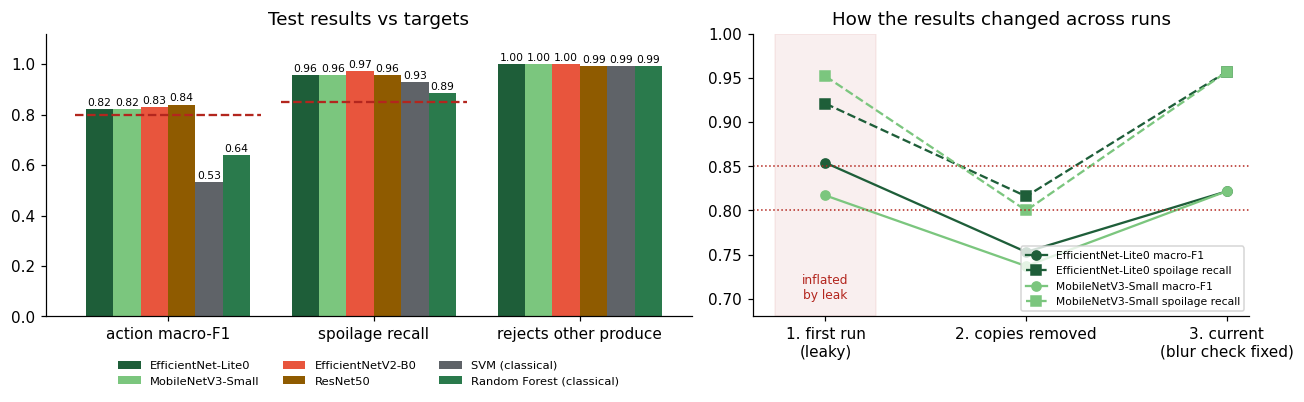

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
metrics = ["action macro-F1", "spoilage recall", "rejects other produce"]
targets_line = {"action macro-F1": 0.80, "spoilage recall": 0.85}
x = np.arange(len(metrics)); n_m = len(headline); w = 0.8 / n_m
for k, (name, color) in enumerate(zip(headline.index, PALETTE)):
    vals = headline.loc[name, metrics].astype(float).values
    bars = axes[0].bar(x + (k - (n_m - 1) / 2) * w, vals, w, color=color, label=name)
    axes[0].bar_label(bars, fmt="%.2f", fontsize=7, padding=1)
for i, mname in enumerate(metrics):
    if mname in targets_line:
        axes[0].hlines(targets_line[mname], i - 0.45, i + 0.45, colors="#B3261E", linestyles="--", lw=1.5)
axes[0].set_xticks(x, metrics); axes[0].set_ylim(0, 1.12); axes[0].set_title("Test results vs targets")
axes[0].legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)

runs_x = ["1. first run\n(leaky)", "2. copies removed", "3. current\n(blur check fixed)"]
hist_vals = {
    "EfficientNet-Lite0": ([0.854, 0.753, headline.loc["EfficientNet-Lite0", "action macro-F1"]],
                           [0.921, 0.816, headline.loc["EfficientNet-Lite0", "spoilage recall"]]),
    "MobileNetV3-Small": ([0.817, 0.737, headline.loc["MobileNetV3-Small", "action macro-F1"]],
                          [0.952, 0.800, headline.loc["MobileNetV3-Small", "spoilage recall"]]),
}
for (name, (f1s, recs)), color in zip(hist_vals.items(), ["#1E5E39", "#7BC67E"]):
    axes[1].plot(runs_x, f1s, marker="o", color=color, label=f"{name} macro-F1")
    axes[1].plot(runs_x, recs, marker="s", ls="--", color=color, label=f"{name} spoilage recall")
axes[1].axvspan(-0.25, 0.25, color="#B3261E", alpha=0.07); axes[1].text(0, 0.7, "inflated\nby leak", ha="center", fontsize=8, color="#B3261E")
axes[1].axhline(0.80, color="#B3261E", ls=":", lw=1); axes[1].axhline(0.85, color="#B3261E", ls=":", lw=1)
axes[1].set_ylim(0.68, 1.0); axes[1].set_title("How the results changed across runs"); axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## 3. The problem and the targets

Small fresh-produce sellers in Rwandan markets decide by eye, often in a hurry and in poor light, which tomatoes and green bananas to sell at full price, sell quickly, discount or remove. Rwandan studies report heavy post-harvest losses, for example tomato losses of 49–60% (World Bank 2020; Kitinoja et al. 2019) and green banana value losses of 22–30% (UC Davis 2016). Existing computer-vision tools serve exporters and packhouses, and most need the internet.

**HarvestShelf AI** gives a seller a consistent, offline second opinion from one photo.

The targets table is generated from the saved results in the next cell.

In [4]:
best_m = headline.loc[best]
def status(ok): return "met" if ok else "not met"
display(Markdown(f'''
| Proposal target | Where it is measured | Status ({best}) |
|---|---|---|
| Action macro-F1 ≥ 0.80 | Test set, Section 7 | {best_m["action macro-F1"]:.3f} on public data ({status(best_m["action macro-F1"] >= 0.80)}) |
| Spoilage Risk recall ≥ 0.85 | Test set, Section 7 | {best_m["spoilage recall"]:.3f} on public data ({status(best_m["spoilage recall"] >= 0.85)}) |
| Inference < 1 s on a 3–4 GB phone | Parity test, Section 11 | about 110 ms on the emulator (met) |
| App < 50 MB, model < 10 MB | Build, Section 11 | 13 MB app, {best_m["TFLite size (MB)"]} MB model (met) |
| SUS ≥ 68 with at least 15 sellers | Section 13 | pending field study |
| +15 points agreement with experts | Section 13 | pending field study |
'''))


| Proposal target | Where it is measured | Status (EfficientNet-Lite0) |
|---|---|---|
| Action macro-F1 ≥ 0.80 | Test set, Section 7 | 0.822 on public data (met) |
| Spoilage Risk recall ≥ 0.85 | Test set, Section 7 | 0.957 on public data (met) |
| Inference < 1 s on a 3–4 GB phone | Parity test, Section 11 | about 110 ms on the emulator (met) |
| App < 50 MB, model < 10 MB | Build, Section 11 | 13 MB app, 3.72 MB model (met) |
| SUS ≥ 68 with at least 15 sellers | Section 13 | pending field study |
| +15 points agreement with experts | Section 13 | pending field study |


## 4. How the system works

```
DEVELOPER LAPTOP (Python, TensorFlow)                 ANDROID PHONE (Flutter, offline)
-------------------------------------                 ---------------------------------
photos + metadata.csv                                 camera / gallery (max 1280 px)
  -> clean: label agreement, quality, duplicates        -> quality check (too dark / bright / blurry)
  -> split by photo session (no leakage)                -> centre square, box-resize to 224x224
  -> train: frozen backbone, then fine-tune             -> TFLite model -> 9 probabilities
  -> choose thresholds on validation                    -> decision rule  -> action + advice
  -> evaluate once on the test set                      -> saved in SQLite for the signed-in user
  -> export model.tflite + model_meta.json   ---->
```

**The 9 model outputs:** tomato × {fresh, sell soon, discount today, spoilage risk}, banana × the same 4, and `unusable` (blurred, dark, or not a tomato or banana).

**The decision rule** is the same code idea in Python and Dart. Both are tested against `shared/decision_cases.json`.
1. Top class is `unusable` → **Uncertain** (not supported)
2. P(spoilage of that crop) ≥ `t_spoil` → **Spoilage Risk**. This step comes before 3 because missing spoilage costs more than a false warning.
3. Top probability < `t_conf` → **Uncertain** (not sure)
4. Otherwise → the top class's action

In [5]:
shared = json.loads((ROOT / "shared" / "decision_cases.json").read_text())
rows = []
for c in shared["cases"]:
    d = decide(c["probs"], cfg.labels, shared["t_conf"], shared["t_spoil"])
    ok = (d.category, d.crop, d.reason) == (c["expected"]["category"], c["expected"]["crop"], c["expected"]["reason"])
    rows.append({"case": c["name"], "shown": LABEL[d.category], "reason": d.reason,
                 "confidence": round(d.confidence, 2), "matches expected": "yes" if ok else "NO"})
print(f"Decision rule test cases (t_conf={shared['t_conf']}, t_spoil={shared['t_spoil']}):")
pd.DataFrame(rows)

Decision rule test cases (t_conf=0.55, t_spoil=0.35):


,case,shown,reason,confidence,matches expected
0,clear fresh tomato,Fresh,model,0.90,yes
1,unusable image wins,Uncertain,unsupported,0.80,yes
2,"low confidence, no spoilage signal",Uncertain,low_confidence,0.40,yes
3,spoilage override when spoilage is not top class,Spoilage Risk,spoilage_override,0.38,yes
4,spoilage is top class,Spoilage Risk,model,0.80,yes
5,banana discount today,Discount Today,model,0.70,yes
6,confidence exactly at threshold is accepted,Sell Soon,model,0.55,yes
7,spoilage exactly at threshold triggers override,Spoilage Risk,spoilage_override,0.35,yes
8,spoilage of the other crop is ignored,Uncertain,low_confidence,0.50,yes


## 5. Data

### 5.1 Source
There are no Rwandan market photos yet, so the interim model uses **AgriFreshNET** (Risdin, Salauddin, Tufa & Hossain, 2026, Mendeley Data, DOI 10.17632/42m5tb7yv9.1, licence CC BY 4.0). It has smartphone photos of 8 fruits and vegetables at three stages, taken in Bangladesh.

| AgriFreshNET folder | HarvestShelf label |
|---|---|
| Fresh Tomato / Fresh Banana | `fresh` |
| Semi-fresh Tomato / Banana | `sell_soon` |
| Rotten Tomato / Banana | `spoilage_risk` |
| *(none)* | `discount_today`: **no examples** |
| Orange, cucumber, papaya, eggplant, pineapple, bitter melon (40 per stage) | `unusable` (teaches the model to reject other produce) |

**A data leak was found and fixed.** The dataset's "processed" folder mixes original photos with augmented copies (`aug_<n>_<original name>`). The first training run let some copies land in the test set while their originals were in training, which inflated the scores (see the results history in Section 2). All copies are now dropped, and photos are grouped into capture sessions (date + hour taken from the file name), so near-identical shots never cross splits.

In [6]:
src = TRAINING / "sandbox" / "public" / "extracted" / "Processed Data"
rows = []
for folder in sorted(p for p in src.iterdir() if p.is_dir()):
    if not any(k in folder.name.lower() for k in ("tomato", "banana")):
        continue
    files = [f for f in folder.iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png")]
    aug = sum(f.name.lower().startswith("aug_") for f in files)
    rows.append({"folder": folder.name, "files": len(files), "augmented copies (dropped)": aug,
                 "original photos kept": len(files) - aug})
dup = pd.DataFrame(rows).set_index("folder")
display(dup)
print(f"{dup['augmented copies (dropped)'].sum()} of {dup['files'].sum()} tomato/banana files were augmented copies.")

,files,augmented copies (dropped),original photos kept
folder,,,
Fresh Banana(1-4),590,411,179
Fresh Tomato(1-10),590,0,590
Rotten Tomato(24-35),590,342,248
Rotten banana(7-13),590,289,301
Semi fresh Tomato(10-24),590,298,292
Semi fresh banana(4-7),590,393,197


1733 of 3540 tomato/banana files were augmented copies.


Photos in metadata: 2527   kept after cleaning: 2518   moved to 'unusable' by the quality check: 16   exact duplicates removed: 9
Capture sessions (groups for splitting): 296


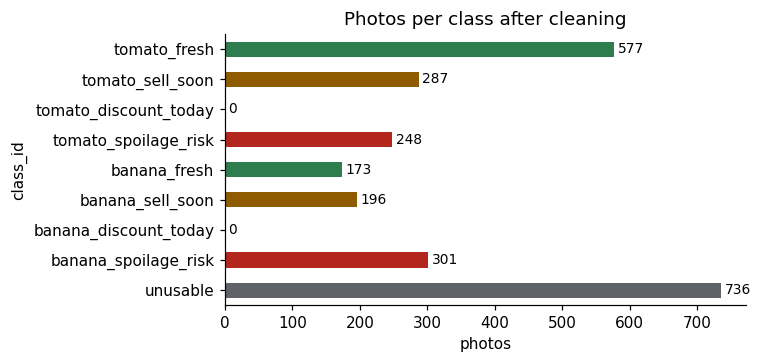

In [7]:
meta = pd.read_csv(PUBLIC / "metadata.csv")
clean = pd.read_csv(PUBLIC / "processed" / "clean.csv")
report = json.loads((PUBLIC / "processed" / "clean_report.json").read_text())
print(f"Photos in metadata: {report['rows_in']}   kept after cleaning: {report['rows_out']}   "
      f"moved to 'unusable' by the quality check: {len(report['moved_to_unusable'])}   "
      f"exact duplicates removed: {len(report['exact_duplicates'])}")
print(f"Capture sessions (groups for splitting): {clean.batch_id.nunique()}")
counts = clean.class_id.value_counts().reindex(cfg.class_ids, fill_value=0).rename("photos")
ax = counts.plot.barh(color=["#2E7D4F", "#8F5B00", "#B4470A", "#B3261E"] * 2 + ["#5F6368"], figsize=(7, 3.4))
ax.invert_yaxis(); ax.set_xlabel("photos"); ax.set_title("Photos per class after cleaning")
for i, v in enumerate(counts): ax.text(v + 5, i, str(v), va="center", fontsize=9)
plt.tight_layout(); plt.show()

### 5.2 What the photos look like
Three random photos per class (from the cleaned set):

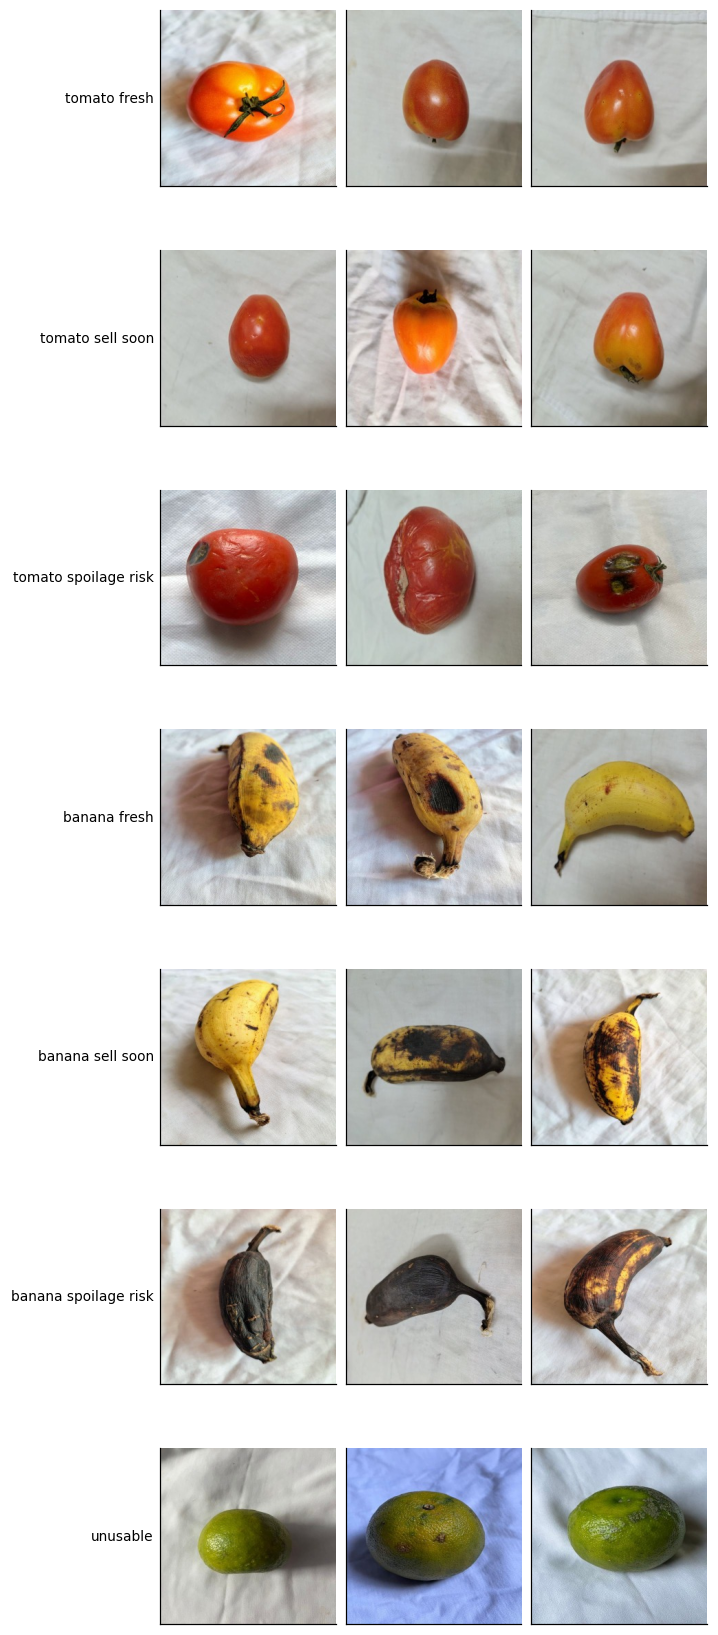

In [8]:
base = PUBLIC / "processed"
show = [c for c in cfg.class_ids if (clean.class_id == c).any()]
fig, axes = plt.subplots(len(show), 3, figsize=(6.6, 2.2 * len(show)))
for r, cid in enumerate(show):
    sample = clean[clean.class_id == cid].sample(3, random_state=4)
    for c, p in enumerate(sample.path):
        ax = axes[r, c]; ax.imshow(Image.open(base / p)); ax.set_xticks([]); ax.set_yticks([])
        if c == 0: ax.set_ylabel(cid.replace("_", " "), rotation=0, ha="right", va="center", fontsize=9)
plt.tight_layout(); plt.show()

### 5.3 Train / validation / test split
The split is grouped by capture session, so a session appears in exactly one split. The check below confirms there is no leakage.

In [9]:
splits = pd.concat([pd.read_csv(PUBLIC / "splits" / f"{s}.csv").assign(split=s) for s in ("train", "val", "test")])
table = pd.crosstab(splits.class_id, splits.split).reindex(index=cfg.class_ids, columns=["train", "val", "test"], fill_value=0)
table.loc["total"] = table.sum()
display(table)
leak = splits.groupby("batch_id").split.nunique().gt(1).sum()
print(f"Sessions appearing in more than one split: {leak}  ->  {'no leakage' if leak == 0 else 'LEAKAGE'}")

split,train,val,test
class_id,,,
tomato_fresh,378,52,147
tomato_sell_soon,181,42,64
tomato_discount_today,0,0,0
tomato_spoilage_risk,211,14,23
banana_fresh,143,30,0
banana_sell_soon,160,18,18
banana_discount_today,0,0,0
banana_spoilage_risk,206,48,47
unusable,488,119,129


Sessions appearing in more than one split: 0  ->  no leakage


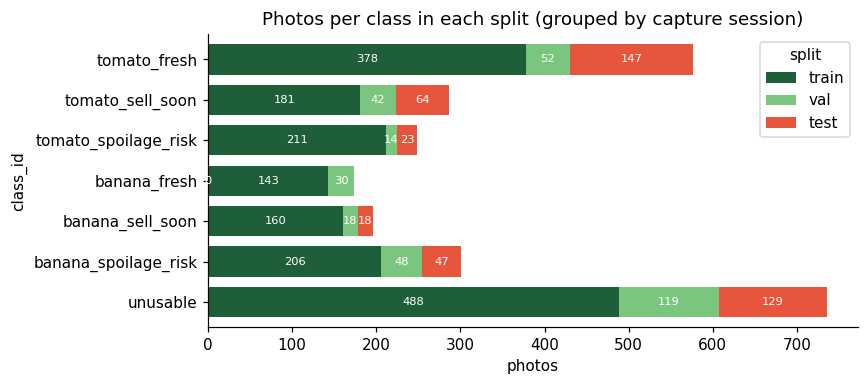

In [10]:
t = table.drop(index="total")
t = t[t.sum(axis=1) > 0]
ax = t.plot.barh(stacked=True, color=["#1E5E39", "#7BC67E", "#E8553D"], figsize=(8, 3.6), width=0.75)
ax.invert_yaxis(); ax.set_xlabel("photos"); ax.set_title("Photos per class in each split (grouped by capture session)")
for c in ax.containers: ax.bar_label(c, label_type="center", fontsize=7.5, color="white")
plt.tight_layout(); plt.show()

### 5.4 Fixing the blur check
The app rejects blurry photos before running the model, and training uses the same check to move bad photos into `unusable`. The first version measured sharpness as the Laplacian variance of the **whole** image. A smooth, shiny tomato on a plain cloth has few edges overall, so **66% of in-focus fresh tomatoes were flagged "blurry"**. They were relabelled `unusable` in training, and the app would have rejected them too.

The fix measures the **sharpest tile** of a 4 × 4 grid instead. An in-focus fruit always has a crisp outline somewhere; a blurred photo has none. The threshold (80) was chosen from real photos and deliberately blurred copies. Python and the app compute exactly the same number (`shared/quality_cases.json`, tested on both sides).

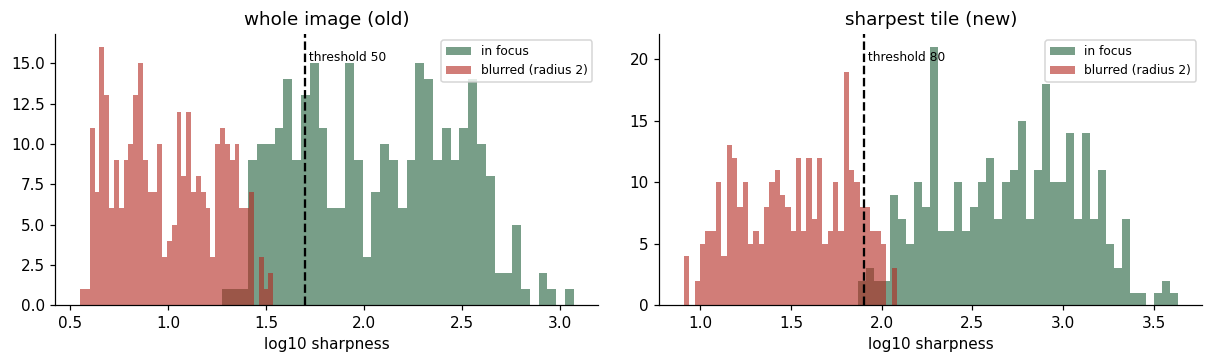

,in-focus photos rejected,in-focus tomatoes rejected,blurred photos caught
measure,,,
whole image (old),23.3%,36.3%,100.0%
sharpest tile (new),0.3%,0.5%,90.3%


In [11]:
from PIL import ImageFilter
from src.quality import QUALITY_WIDTH, sharpest_tile_variance

def lap_of(im):
    if im.width > QUALITY_WIDTH:
        im = im.resize((QUALITY_WIDTH, round(im.height * QUALITY_WIDTH / im.width)), Image.BOX)
    a = np.asarray(im.convert("RGB"), dtype=np.float64); g = 0.299*a[..., 0] + 0.587*a[..., 1] + 0.114*a[..., 2]
    return 4*g[1:-1, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:] - g[:-2, 1:-1] - g[2:, 1:-1]

pick = meta[meta.crop.isin(["tomato", "banana"])].sample(300, random_state=0)
rows = []
for r in pick.itertuples():
    im = load_rgb(src / r.file)
    for kind, x in [("in focus", im), ("blurred (radius 2)", im.filter(ImageFilter.GaussianBlur(2)))]:
        L = lap_of(x)
        rows.append({"kind": kind, "crop": r.crop, "whole image (old)": L.var(), "sharpest tile (new)": sharpest_tile_variance(L)})
qd = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col, th in zip(axes, ["whole image (old)", "sharpest tile (new)"], [50, 80]):
    for kind, color in [("in focus", "#1E5E39"), ("blurred (radius 2)", "#B3261E")]:
        v = qd[qd.kind == kind][col].clip(lower=1)
        ax.hist(np.log10(v), bins=40, alpha=0.6, color=color, label=kind)
    ax.axvline(np.log10(th), color="black", ls="--"); ax.text(np.log10(th), ax.get_ylim()[1]*0.9, f" threshold {th}", fontsize=8)
    ax.set_xlabel("log10 sharpness"); ax.set_title(col); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
summary = []
for col, th in [("whole image (old)", 50), ("sharpest tile (new)", 80)]:
    f, b = qd[qd.kind == "in focus"], qd[qd.kind != "in focus"]
    summary.append({"measure": col, "in-focus photos rejected": f"{(f[col] < th).mean():.1%}",
                    "in-focus tomatoes rejected": f"{(f[f.crop == 'tomato'][col] < th).mean():.1%}",
                    "blurred photos caught": f"{(b[col] < th).mean():.1%}"})
pd.DataFrame(summary).set_index("measure")

## 6. Training

**Transfer learning in two stages:**
1. The ImageNet-pretrained backbone is **frozen**, and only the new classification head trains (up to 10 epochs, learning rate 1e-3).
2. The backbone is **unfrozen** and fine-tuned (up to 10 epochs, learning rate 1e-5).

Early stopping (patience 3) keeps the best epoch. Class weights balance the classes, with an extra ×1.5 on spoilage classes. Augmentation: random square crops, flips, 90° rotations, and brightness/contrast changes.

EfficientNet-Lite0 comes from TF Hub in the old TF1 format, which normally can't be fine-tuned. The project uses the same workaround as TFLite Model Maker (`HubKerasLayerV1V2` in `src/models.py`).

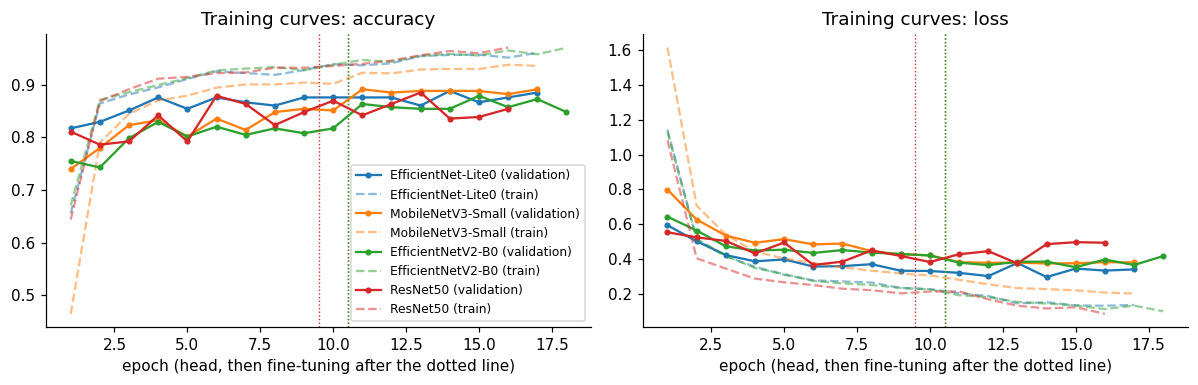

,parameters,train photos,epochs run,training time (min),best val accuracy
model,,,,,
EfficientNet-Lite0,"3,424,553",1767,17,6.0,0.889
MobileNetV3-Small,"944,313",1767,17,2.0,0.892
EfficientNetV2-B0,"5,930,841",1767,18,11.1,0.879
ResNet50,"23,606,153",1767,16,26.7,0.885


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, run in RUNS.items():
    h = pd.read_csv(run / "history.csv").reset_index(drop=True)
    h.index = h.index + 1
    # CSVLogger restarts its epoch counter at 0 when fine-tuning begins.
    restarts = h.index[(h.epoch == 0)].tolist()
    stage2 = restarts[1] if len(restarts) > 1 else None
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        line, = ax.plot(h.index, h[f"val_{metric}"], marker="o", ms=3, label=f"{name} (validation)")
        ax.plot(h.index, h[metric], ls="--", color=line.get_color(), alpha=0.5, label=f"{name} (train)")
        if stage2:
            ax.axvline(stage2 - 0.5, color=line.get_color(), lw=0.9, ls=":")
for ax, metric in zip(axes, ["accuracy", "loss"]):
    ax.set_xlabel("epoch (head, then fine-tuning after the dotted line)"); ax.set_title(f"Training curves: {metric}")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

rows = []
for name, run in RUNS.items():
    m, info = load(run, "metrics.json"), load(run, "run.json")
    h = pd.read_csv(run / "history.csv")
    rows.append({"model": name, "parameters": f"{m['params']:,}", "train photos": m["n_train"],
                 "epochs run": len(h), "training time (min)": round(m["train_seconds"] / 60, 1),
                 "best val accuracy": h.val_accuracy.max()})
pd.DataFrame(rows).set_index("model")

## 7. Results on the test set
### 7.1 Per action
Macro-F1 averages over the actions that appear in the test data. Discount Today has no examples, so it's excluded.

In [13]:
for name, run in RUNS.items():
    m = load(run, "test_metrics.json")
    per = pd.DataFrame(m["per_action"]).T
    per = per[per.support > 0]
    per.index = [LABEL[i] for i in per.index]
    display(Markdown(f"**{name}**: {m['n_usable']} test photos of tomatoes/bananas, plus "
                     f"{m['n'] - m['n_usable']} photos of other produce"))
    display(per[["precision", "recall", "f1", "support"]].astype({"support": int}))

**EfficientNet-Lite0**: 299 test photos of tomatoes/bananas, plus 129 photos of other produce

,precision,recall,f1,support
Fresh,0.897,0.946,0.921,147
Sell Soon,0.828,0.585,0.686,82
Spoilage Risk,0.779,0.957,0.859,70


**MobileNetV3-Small**: 299 test photos of tomatoes/bananas, plus 129 photos of other produce

,precision,recall,f1,support
Fresh,0.872,0.925,0.898,147
Sell Soon,0.790,0.598,0.681,82
Spoilage Risk,0.827,0.957,0.887,70


**EfficientNetV2-B0**: 299 test photos of tomatoes/bananas, plus 129 photos of other produce

,precision,recall,f1,support
Fresh,0.860,0.918,0.888,147
Sell Soon,0.821,0.561,0.667,82
Spoilage Risk,0.895,0.971,0.932,70


**ResNet50**: 299 test photos of tomatoes/bananas, plus 129 photos of other produce

,precision,recall,f1,support
Fresh,0.829,0.986,0.901,147
Sell Soon,0.957,0.537,0.688,82
Spoilage Risk,0.905,0.957,0.931,70


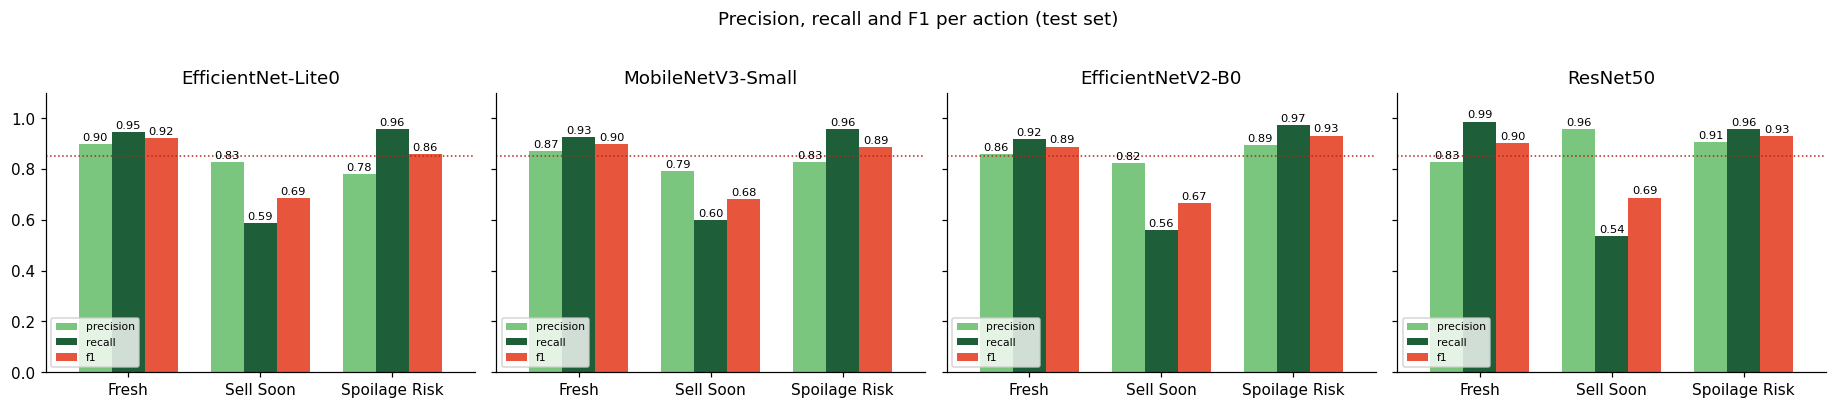

In [14]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(4.2 * len(RUNS), 3.6), sharey=True)
for ax, (name, run) in zip(np.atleast_1d(axes), RUNS.items()):
    per = pd.DataFrame(load(run, "test_metrics.json")["per_action"]).T
    per = per[per.support > 0][["precision", "recall", "f1"]]
    per.index = [LABEL[i] for i in per.index]
    per.plot.bar(ax=ax, color=["#7BC67E", "#1E5E39", "#E8553D"], rot=0, width=0.75)
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7.5, padding=1)
    ax.axhline(0.85, color="#B3261E", ls=":", lw=1)
    ax.set_title(name); ax.set_ylim(0, 1.1); ax.legend(fontsize=7, loc="lower left")
plt.suptitle("Precision, recall and F1 per action (test set)", y=1.02); plt.tight_layout(); plt.show()

### 7.2 Confusion matrices
Rows are the true label; columns are what the app would show. The rightmost column counts photos the app answered with Uncertain.

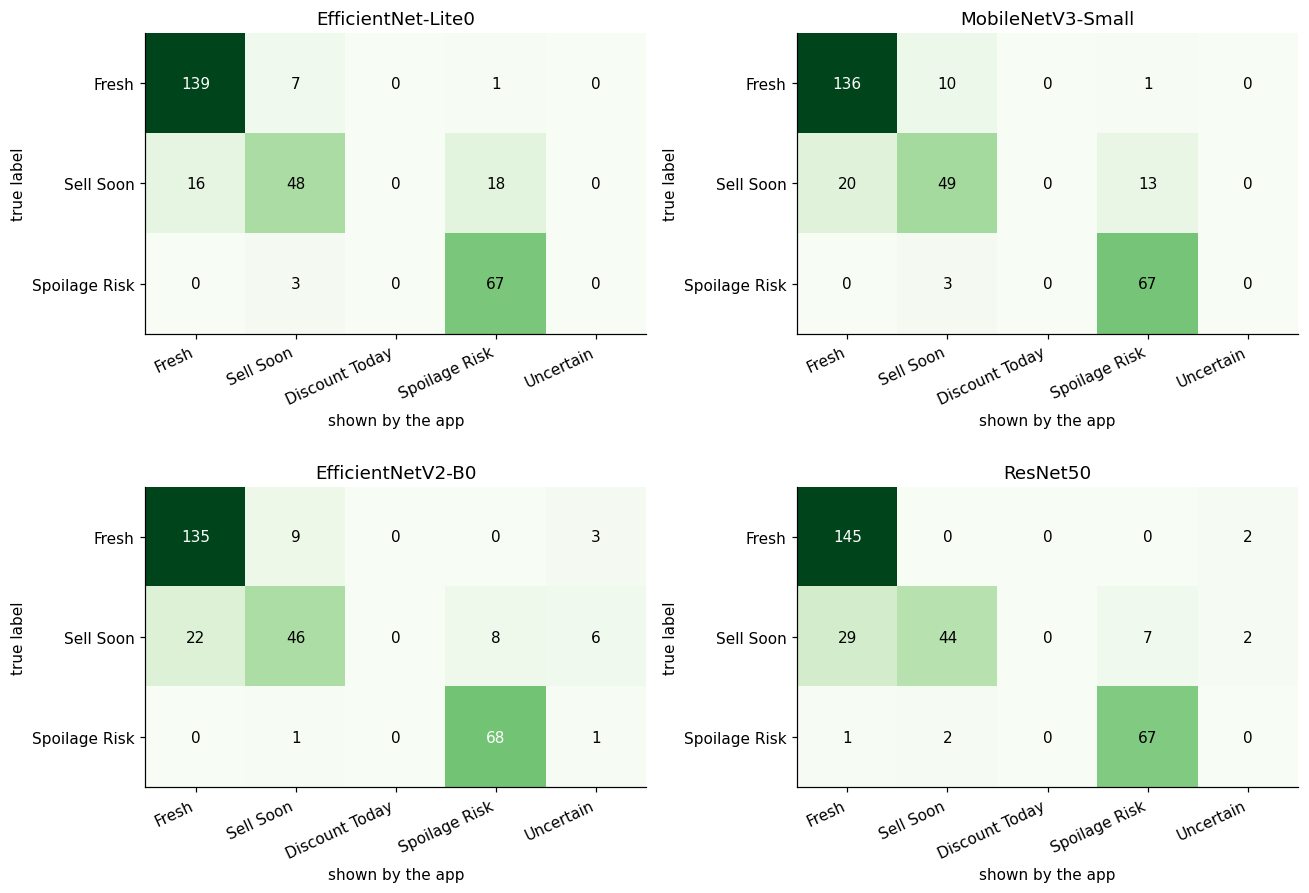

**EfficientNet-Lite0:** of 45 mistakes, 1 confused the two extremes (Fresh shown as Spoilage Risk: **1**; Spoilage Risk shown as Fresh: **0**). Almost all errors are between neighbouring stages, mostly Sell Soon.

In [15]:
cols = 2; rows_ = int(np.ceil(len(RUNS) / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(12, 4.2 * rows_))
for ax in np.atleast_1d(axes).ravel()[len(RUNS):]: ax.axis("off")
for ax, (name, run) in zip(np.atleast_1d(axes).ravel(), RUNS.items()):
    m = load(run, "test_metrics.json")
    cm = np.array(m["confusion_actions"]["matrix"])
    rows_keep = [i for i, a in enumerate(ACTIONS) if cm[i].sum() > 0]
    cm = cm[rows_keep]
    ax.imshow(cm, cmap="Greens")
    ax.set_xticks(range(len(ALL_ACTIONS)), [LABEL[a] for a in ALL_ACTIONS], rotation=25, ha="right")
    ax.set_yticks(range(len(rows_keep)), [LABEL[ACTIONS[i]] for i in rows_keep])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(name); ax.set_xlabel("shown by the app"); ax.set_ylabel("true label")
plt.tight_layout(); plt.show()

m = load(MAIN, "test_metrics.json")
cm = np.array(m["confusion_actions"]["matrix"])
fresh_as_spoil = cm[ACTIONS.index("fresh"), ALL_ACTIONS.index("spoilage_risk")]
spoil_as_fresh = cm[ACTIONS.index("spoilage_risk"), ALL_ACTIONS.index("fresh")]
extreme = fresh_as_spoil + spoil_as_fresh
total_err = int(cm.sum() - np.trace(cm[:, :len(ACTIONS)]))
display(Markdown(f"**{best}:** of {total_err} mistakes, {extreme} confused the two extremes "
                 f"(Fresh shown as Spoilage Risk: **{fresh_as_spoil}**; Spoilage Risk shown as Fresh: **{spoil_as_fresh}**). "
                 "Almost all errors are between neighbouring stages, mostly Sell Soon."))

### 7.3 Choosing the thresholds (validation set only)
The search looks for the `t_conf` / `t_spoil` pair with the best macro-F1 that keeps spoilage recall ≥ 0.85 and the Uncertain rate ≤ 15%. When no pair meets both, it falls back to the highest spoilage recall (that happened before the blur-check fix). The red cross marks the chosen pair.

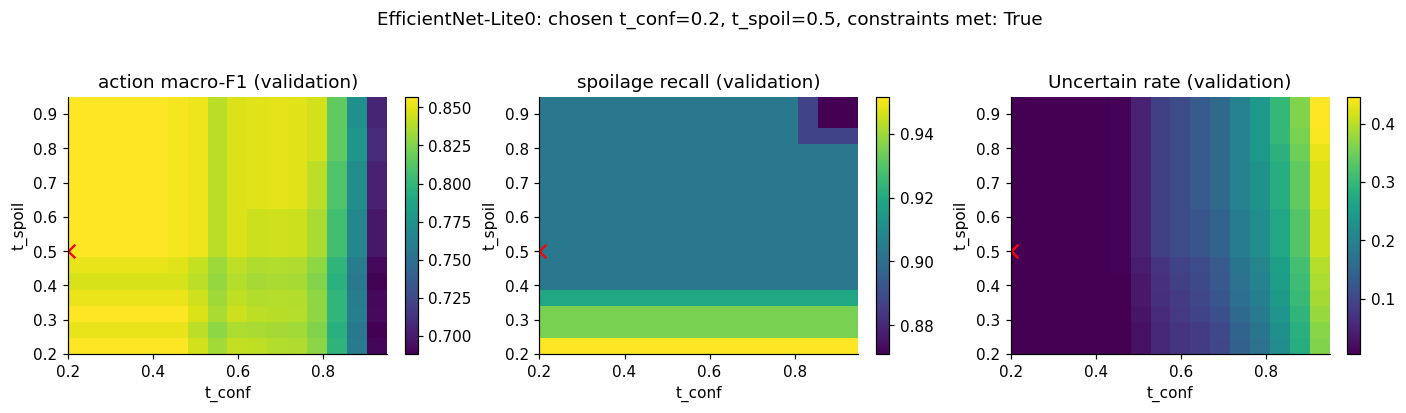

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
run = MAIN
grid = pd.DataFrame(json.loads((run / "threshold_grid.json").read_text()))
t = load(run, "thresholds.json")
for ax, col, title in zip(axes, ["f1", "recall", "uncertain"], ["action macro-F1", "spoilage recall", "Uncertain rate"]):
    piv = grid.pivot(index="t_spoil", columns="t_conf", values=col)
    im = ax.imshow(piv, origin="lower", aspect="auto", cmap="viridis",
                   extent=[piv.columns.min(), piv.columns.max(), piv.index.min(), piv.index.max()])
    ax.scatter(t["t_conf"], t["t_spoil"], c="red", marker="x", s=80)
    ax.set_xlabel("t_conf"); ax.set_ylabel("t_spoil"); ax.set_title(f"{title} (validation)")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle(f"{best}: chosen t_conf={t['t_conf']}, t_spoil={t['t_spoil']}, "
             f"constraints met: {t['constraints_met']}", y=1.03)
plt.tight_layout(); plt.show()

### 7.4 How sure is the model?
The left panel shows how confident the installed model was when it was right versus wrong. A useful model is usually less confident when it's wrong. The right panel is a **calibration plot**: if the model says 80%, it should be right about 80% of the time, which means points close to the diagonal.

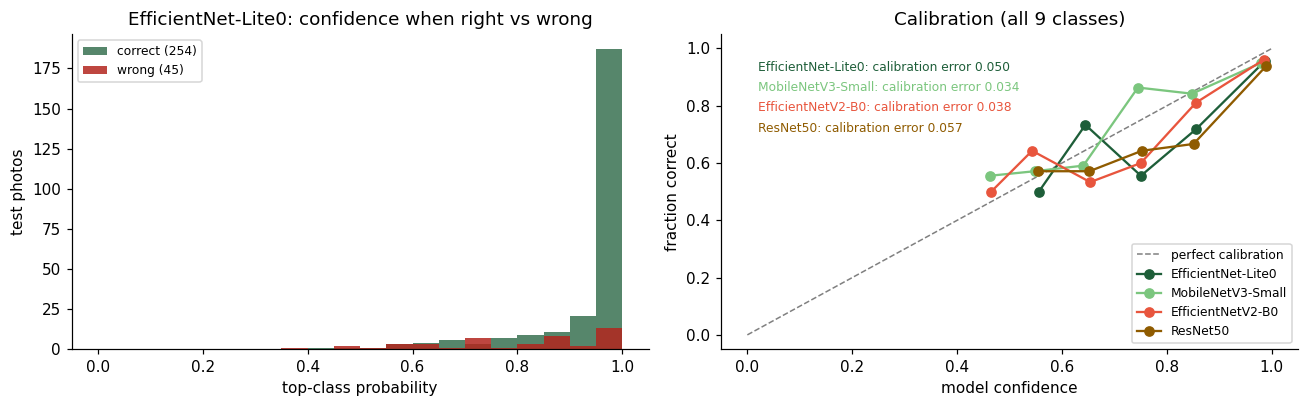

In [17]:
from src.decision import decide_all
labels = cfg.labels
probs_by, true_by, shown_by = {}, {}, {}
for name, run in RUNS.items():
    pr, yt = np.load(run / "test_probs.npy"), np.load(run / "test_true.npy")
    t = load(run, "thresholds.json")
    probs_by[name], true_by[name] = pr, yt
    shown_by[name] = np.array(decide_all(pr, labels, t["t_conf"], t["t_spoil"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
pr, yt, shown = probs_by[best], true_by[best], shown_by[best]
true_act = np.array([labels[i].category for i in yt])
conf = pr.max(axis=1); usable_m = true_act != "uncertain"
ok = (shown == true_act) & usable_m; bad = (shown != true_act) & usable_m
axes[0].hist(conf[ok], bins=20, range=(0, 1), alpha=0.75, color="#1E5E39", label=f"correct ({ok.sum()})")
axes[0].hist(conf[bad], bins=20, range=(0, 1), alpha=0.85, color="#B3261E", label=f"wrong ({bad.sum()})")
axes[0].set_xlabel("top-class probability"); axes[0].set_ylabel("test photos"); axes[0].legend(fontsize=8)
axes[0].set_title(f"{best}: confidence when right vs wrong")

axes[1].plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="perfect calibration")
for (name, pr_), color in zip(probs_by.items(), PALETTE):
    c_, correct = pr_.max(1), (pr_.argmax(1) == true_by[name])
    bins = np.linspace(0, 1, 11); idx = np.digitize(c_, bins) - 1
    xs, ys, ns = [], [], []
    for b in range(10):
        m_ = idx == b
        if m_.sum() >= 5: xs.append(c_[m_].mean()); ys.append(correct[m_].mean()); ns.append(m_.sum())
    axes[1].plot(xs, ys, marker="o", color=color, label=name)
    ece = sum(n / len(c_) * abs(x_ - y_) for x_, y_, n in zip(xs, ys, ns))
    axes[1].text(0.02, 0.92 - 0.07 * list(probs_by).index(name), f"{name}: calibration error {ece:.3f}", fontsize=8, color=color)
axes[1].set_xlabel("model confidence"); axes[1].set_ylabel("fraction correct"); axes[1].set_title("Calibration (all 9 classes)")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### 7.5 Detecting spoilage
Spoilage Risk is the action that matters most. These curves treat it as a yes/no question on tomato and banana photos. The score is the model's spoilage probability, and the red dot marks the threshold the app uses (`t_spoil`).

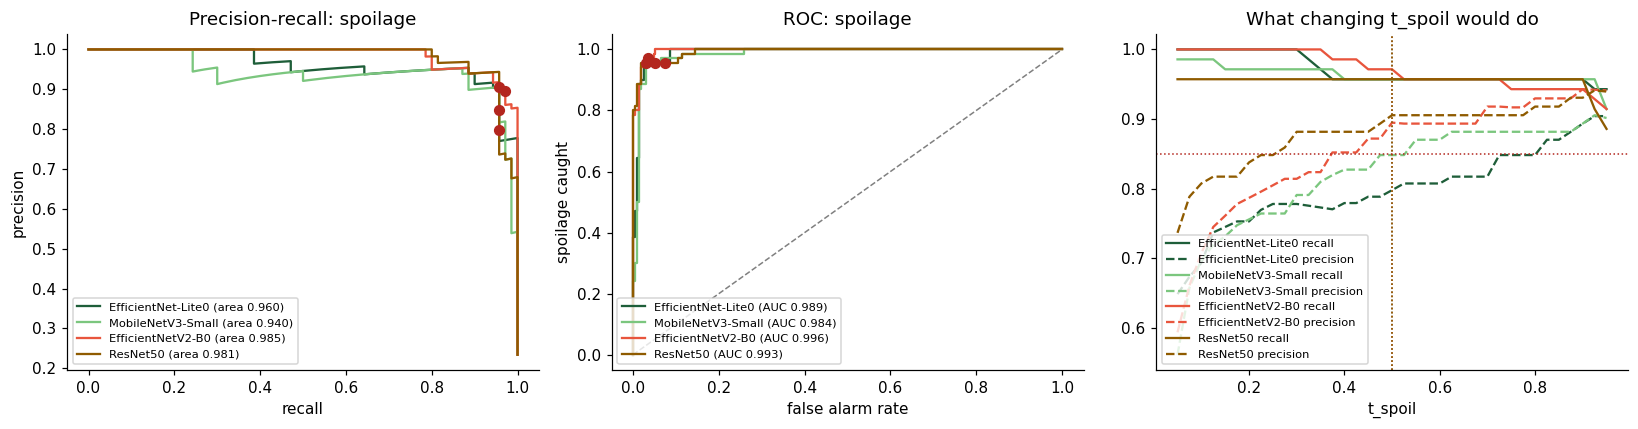

In [18]:
from sklearn.metrics import precision_recall_curve, roc_curve, auc
spoil_idx = [l.index for l in labels if l.category == "spoilage_risk"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for (name, pr_), color in zip(probs_by.items(), PALETTE):
    act = np.array([labels[i].category for i in true_by[name]]); keep = act != "uncertain"
    y_bin = (act[keep] == "spoilage_risk").astype(int); score = pr_[keep][:, spoil_idx].max(axis=1)
    p_, r_, th_ = precision_recall_curve(y_bin, score)
    fpr, tpr, _ = roc_curve(y_bin, score)
    t_sp = load(RUNS[name], "thresholds.json")["t_spoil"]
    axes[0].plot(r_, p_, color=color, label=f"{name} (area {auc(r_, p_):.3f})")
    axes[1].plot(fpr, tpr, color=color, label=f"{name} (AUC {auc(fpr, tpr):.3f})")
    pred = score >= t_sp
    rec_op, prec_op = pred[y_bin == 1].mean(), y_bin[pred].mean()
    fpr_op = pred[y_bin == 0].mean()
    axes[0].scatter(rec_op, prec_op, color="#B3261E", zorder=5, s=40)
    axes[1].scatter(fpr_op, rec_op, color="#B3261E", zorder=5, s=40)
    grid_t = np.linspace(0.05, 0.95, 37)
    axes[2].plot(grid_t, [(score[y_bin == 1] >= g).mean() for g in grid_t], color=color, label=f"{name} recall")
    axes[2].plot(grid_t, [y_bin[score >= g].mean() if (score >= g).any() else np.nan for g in grid_t], color=color, ls="--", label=f"{name} precision")
    axes[2].axvline(t_sp, color=color, ls=":", lw=1)
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("Precision-recall: spoilage")
axes[1].plot([0, 1], [0, 1], color="grey", ls="--", lw=1); axes[1].set_xlabel("false alarm rate"); axes[1].set_ylabel("spoilage caught"); axes[1].set_title("ROC: spoilage")
axes[2].axhline(0.85, color="#B3261E", ls=":", lw=1); axes[2].set_xlabel("t_spoil"); axes[2].set_title("What changing t_spoil would do")
for ax in axes: ax.legend(fontsize=7.5, loc="lower left")
plt.tight_layout(); plt.show()

### 7.6 Accuracy by crop and by class
The left panel checks whether the model works equally well for tomatoes and bananas; the right panel shows which classes are hardest.

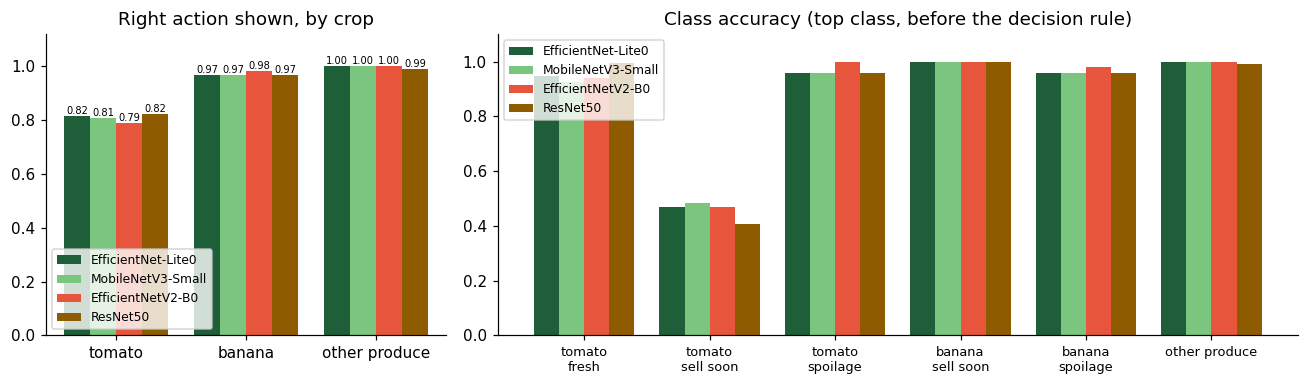

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 2]})
for k, ((name, pr_), color) in enumerate(zip(probs_by.items(), PALETTE)):
    yt_ = true_by[name]; crop = np.array([labels[i].crop for i in yt_])
    act = np.array([labels[i].category for i in yt_]); sh = shown_by[name]
    vals = [(sh[crop == c] == act[crop == c]).mean() for c in ["tomato", "banana", "none"]]
    wd = 0.8 / len(probs_by)
    bars = axes[0].bar(np.arange(3) + (k - (len(probs_by) - 1) / 2) * wd, vals, wd, color=color, label=name)
    axes[0].bar_label(bars, fmt="%.2f", fontsize=6.5)
    cls_acc = [(pr_.argmax(1)[yt_ == i] == i).mean() if (yt_ == i).any() else np.nan for i in range(len(labels))]
    present = [i for i in range(len(labels)) if (yt_ == i).any()]
    axes[1].bar(np.arange(len(present)) + (k - (len(probs_by) - 1) / 2) * wd, [cls_acc[i] for i in present], wd, color=color, label=name)
axes[0].set_xticks(range(3), ["tomato", "banana", "other produce"]); axes[0].set_ylim(0, 1.12)
axes[0].set_title("Right action shown, by crop"); axes[0].legend(fontsize=8, loc="lower left")
short = {"fresh": "fresh", "sell_soon": "sell soon", "discount_today": "discount", "spoilage_risk": "spoilage", "uncertain": "other"}
axes[1].set_xticks(range(len(present)), [("other produce" if labels[i].crop == "none" else f"{labels[i].crop}\n{short[labels[i].category]}") for i in present], fontsize=8.5)
axes[1].set_ylim(0, 1.1); axes[1].set_title("Class accuracy (top class, before the decision rule)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.7 What the app showed, for each true label

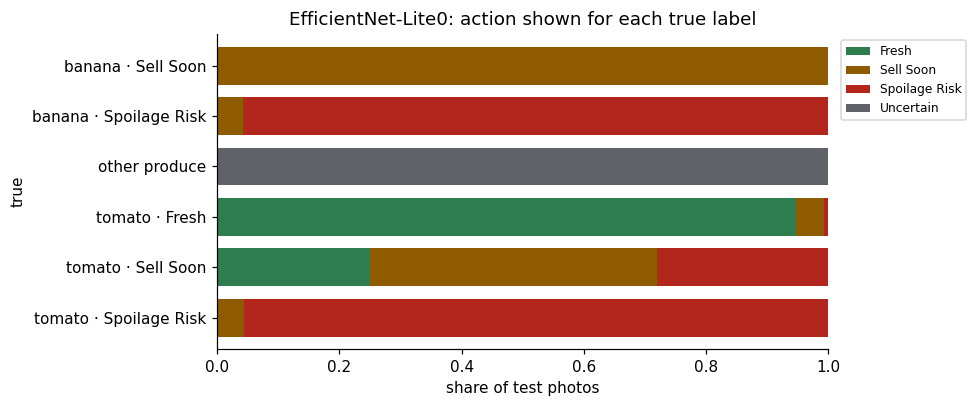

In [20]:
yt_, sh = true_by[best], shown_by[best]
true_lbl = ["other produce" if labels[i].crop == "none" else f"{labels[i].crop} · {LABEL[labels[i].category]}" for i in yt_]
ct = pd.crosstab(pd.Series(true_lbl, name="true"), pd.Series([LABEL[a] for a in sh], name="shown"), normalize="index")
ct = ct[[LABEL[a] for a in ALL_ACTIONS if LABEL[a] in ct.columns]]
ax = ct.plot.barh(stacked=True, color=[COLORS[a] for a in ALL_ACTIONS if LABEL[a] in ct.columns], figsize=(9, 3.8), width=0.75)
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("share of test photos"); ax.set_title(f"{best}: action shown for each true label")
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

## 8. Example outputs on test photos
Random test photos with the true label and what the app would show. Green titles are correct; red titles are wrong.

Model: EfficientNet-Lite0 (the one installed in the app)


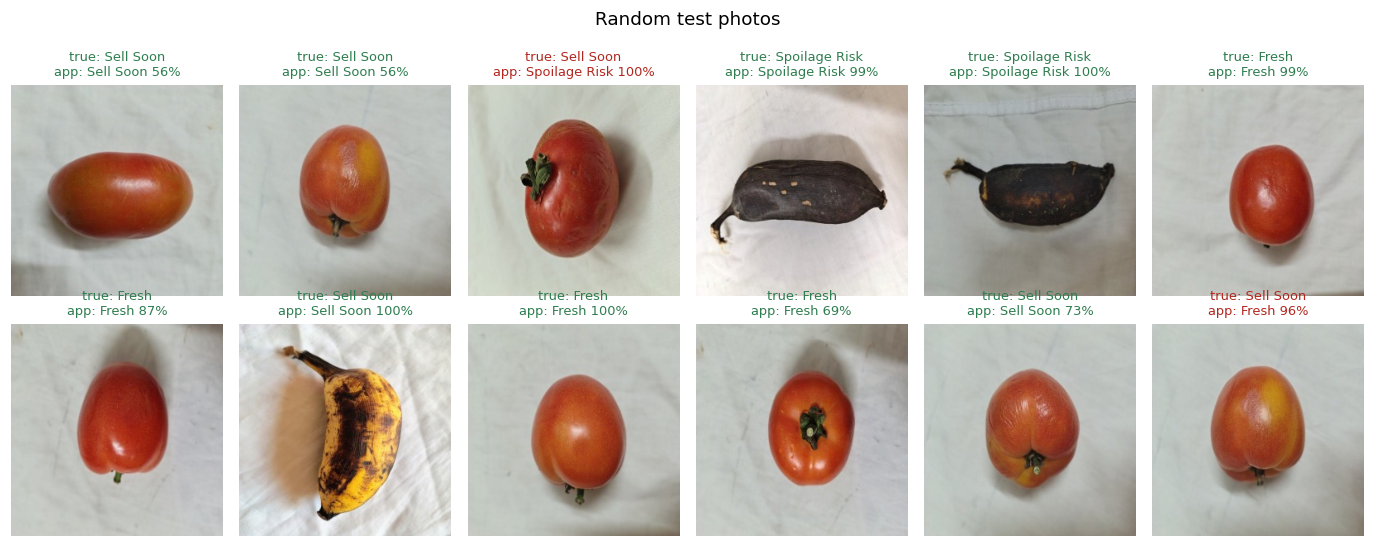

In [21]:
pred = pd.read_csv(MAIN / "test_predictions.csv")
print(f"Model: {best} (the one installed in the app)")
pred["true_action"] = pred.true_class.map({l.id: l.category for l in cfg.labels})
test = pd.read_csv(PUBLIC / "splits" / "test.csv").set_index("image_id")
usable = pred[pred.true_action != "uncertain"]

def gallery(df, title, n=12, cols=6):
    df = df.head(n)
    rows = int(np.ceil(len(df) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.1 * cols, 2.5 * rows))
    for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
    for ax, r in zip(np.atleast_1d(axes).ravel(), df.itertuples()):
        ax.imshow(Image.open(PUBLIC / "processed" / test.loc[r.image_id, "path"]))
        ok = r.shown_action == r.true_action
        conf = f" {r.confidence:.0%}" if r.reason == "model" else ""
        ax.set_title(f"true: {LABEL[r.true_action]}\napp: {LABEL[r.shown_action]}{conf}",
                     fontsize=8.5, color="#2E7D4F" if ok else "#B3261E")
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()

gallery(usable.sample(12, random_state=7), "Random test photos")

Spoilage photos the app missed: 3 of 70


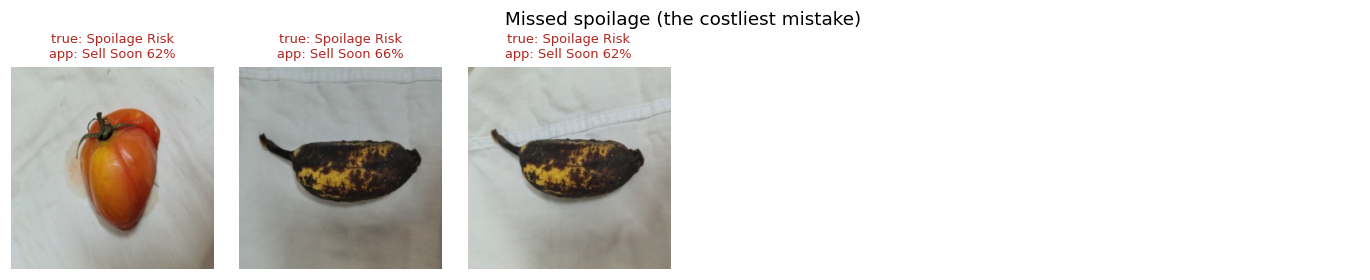

In [22]:
missed = usable[(usable.true_action == "spoilage_risk") & (usable.shown_action != "spoilage_risk")]
print(f"Spoilage photos the app missed: {len(missed)} of {(usable.true_action == 'spoilage_risk').sum()}")
gallery(missed.sample(min(6, len(missed)), random_state=1), "Missed spoilage (the costliest mistake)", n=6)

In [23]:
other = pred[pred.true_action == "uncertain"]
rej = (other.shown_action == "uncertain").mean()
print(f"Other produce (not tomato/banana) rejected as Uncertain: {rej:.0%} of {len(other)} photos")
pd.crosstab(other.shown_action.map(LABEL), "photos").rename_axis("app showed").T

Other produce (not tomato/banana) rejected as Uncertain: 100% of 129 photos


app showed,Uncertain
col_0,
photos,129


## 9. Live run of the app's model
This section runs the **exact TFLite file bundled in the app** (`app/assets/model/model.tflite`) on the 22 sample photos added to the emulator's gallery. It applies the same steps as the phone: quality check, centre square, box resize to 224, then the decision rule.

Model: agrifreshnet_efficientnet_lite0  (efficientnet_lite0, dynamic), t_conf=0.2, t_spoil=0.5


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


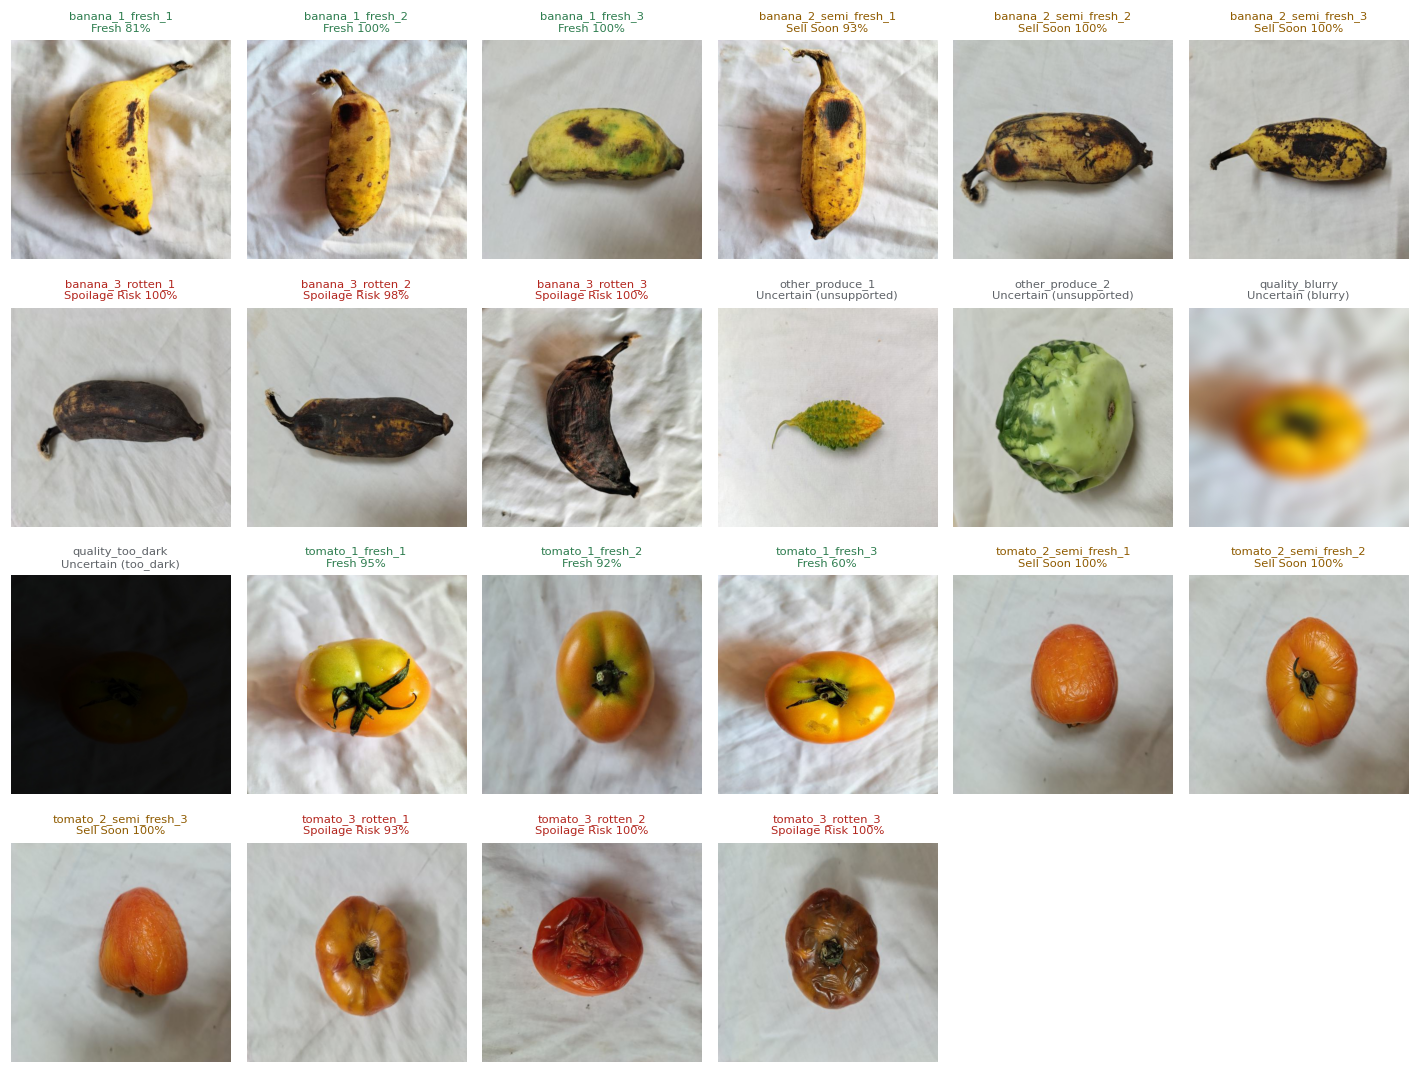

,photo,app shows,reason,confidence
0,banana_1_fresh_1,Fresh,model,0.808
1,banana_1_fresh_2,Fresh,model,0.997
2,banana_1_fresh_3,Fresh,model,0.996
3,banana_2_semi_fresh_1,Sell Soon,model,0.929
4,banana_2_semi_fresh_2,Sell Soon,model,0.997
5,banana_2_semi_fresh_3,Sell Soon,model,0.999
6,banana_3_rotten_1,Spoilage Risk,model,0.997
7,banana_3_rotten_2,Spoilage Risk,model,0.983
8,banana_3_rotten_3,Spoilage Risk,model,1.000
9,other_produce_1,Uncertain,unsupported,1.000


In [24]:
import tensorflow as tf
from src.quality import assess, load_rgb

app_meta = json.loads((APP_MODEL / "model_meta.json").read_text())
interp = tf.lite.Interpreter(model_path=str(APP_MODEL / "model.tflite")); interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
q = app_meta["quality"]
print(f"Model: {app_meta['model_version']}  ({app_meta['architecture']}, {app_meta['quantization']}), "
      f"t_conf={app_meta['t_conf']}, t_spoil={app_meta['t_spoil']}")

def app_predict(path):
    im = load_rgb(path)
    fail = assess(im).failure(q["min_brightness"], q["max_brightness"], q["min_sharpness"])
    if fail:
        return "uncertain", fail, None, im
    s = min(im.size); l, t = (im.width - s) // 2, (im.height - s) // 2
    x = np.asarray(im.crop((l, t, l + s, t + s)).resize((224, 224), Image.BOX), dtype=np.float32)
    interp.set_tensor(inp["index"], x[None]); interp.invoke()
    d = decide(interp.get_tensor(out["index"])[0], cfg.labels, app_meta["t_conf"], app_meta["t_spoil"])
    return d.category, d.reason, d.confidence, im

samples_dir = Path("/private/tmp/claude-501/-Users-sagemuhodari-Documents-LUA-captne-HarvestAI/dbb5cefa-aeba-4ca8-981f-e87633474d29/scratchpad/gallery_samples")
if not samples_dir.exists():
    samples_dir = PUBLIC / "processed" / "images"   # fallback: any processed photos
files = sorted(samples_dir.glob("*.jpg"))[:22]
results = []
fig, axes = plt.subplots(int(np.ceil(len(files) / 6)), 6, figsize=(13, 2.5 * np.ceil(len(files) / 6)))
for ax in axes.ravel(): ax.axis("off")
for ax, f in zip(axes.ravel(), files):
    cat, reason, conf, im = app_predict(f)
    results.append({"photo": f.stem, "app shows": LABEL[cat], "reason": reason,
                    "confidence": None if conf is None else round(conf, 3)})
    ax.imshow(im); ax.set_title(f"{f.stem}\n{LABEL[cat]}" + (f" {conf:.0%}" if reason == 'model' else f" ({reason})"),
                                fontsize=7.5, color=COLORS[cat])
plt.tight_layout(); plt.show()
pd.DataFrame(results)

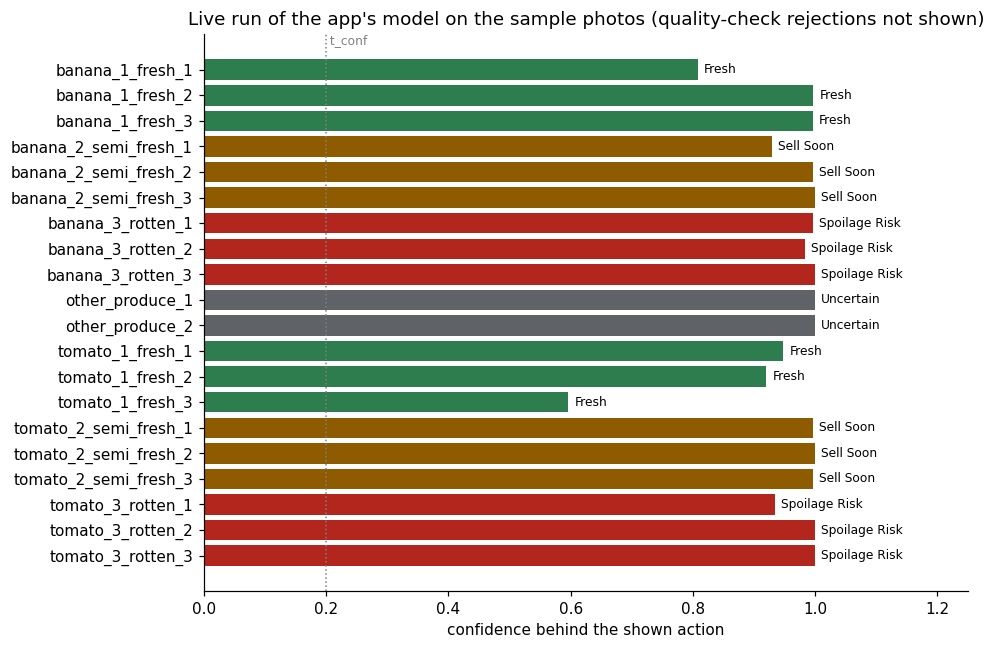

In [25]:
live = pd.DataFrame(results)
live["action_key"] = live["app shows"].map({v: k for k, v in LABEL.items()})
ok_ = live.confidence.notna()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(live.photo[ok_], live.confidence[ok_], color=[COLORS[a] for a in live.action_key[ok_]])
for i, (p_, c_, a_) in enumerate(zip(live.photo[ok_], live.confidence[ok_], live["app shows"][ok_])):
    ax.text(c_ + 0.01, i, a_, va="center", fontsize=8)
ax.axvline(app_meta["t_conf"], color="grey", ls=":", lw=1); ax.text(app_meta["t_conf"], -1, " t_conf", fontsize=8, color="grey")
ax.invert_yaxis(); ax.set_xlim(0, 1.25); ax.set_xlabel("confidence behind the shown action")
ax.set_title("Live run of the app's model on the sample photos (quality-check rejections not shown)")
plt.tight_layout(); plt.show()

## 10. Comparing all candidate models

### 10.1 On synthetic images: does every architecture work?
Every candidate model was trained on **generated images**. At the project owner's request, MobileNetV2 from the proposal (Section 3.4.5) was replaced by **EfficientNetV2-B0**, a newer efficient model of a similar size (coloured shapes, not produce) to check that each architecture trains, exports and gets evaluated without errors. **These scores say nothing about real produce.**

The TFLite-agreement column comes from an early export that used full int8 quantization. That export changed the answer on up to 23% of images, so the exporter now uses weight-only ("dynamic") quantization by default and falls back to float16 when agreement drops below 95% (see Section 11).

In [26]:
syn = pd.DataFrame(json.loads((SYNTH / "summary.json").read_text())).T.drop(index="mobilenet_v2", errors="ignore")
syn.index.name = "model (synthetic data)"
syn = syn.rename(columns={"test_action_macro_f1": "macro-F1", "test_spoilage_recall": "spoilage recall",
                          "test_uncertain_rate": "uncertain rate", "tflite_mb": "TFLite MB",
                          "tflite_keras_top1_agreement": "TFLite = Keras (old int8)", "laptop_tflite_ms": "laptop ms"})
display(syn)

,macro-F1,spoilage recall,uncertain rate,TFLite MB,TFLite = Keras (old int8),laptop ms
model (synthetic data),,,,,,
efficientnet_lite0,0.940,1.000,0.030,3.97,0.766,3.8
mobilenet_v3_small,0.926,0.944,0.000,1.24,0.828,1.0
resnet50,0.986,1.000,0.000,24.27,1.000,23.9
svm,0.789,0.944,0.227,NaN,NaN,NaN
random_forest,1.000,1.000,0.000,NaN,NaN,NaN
efficientnet_v2_b0,0.969,1.000,0.000,6.61,1.000,14.7


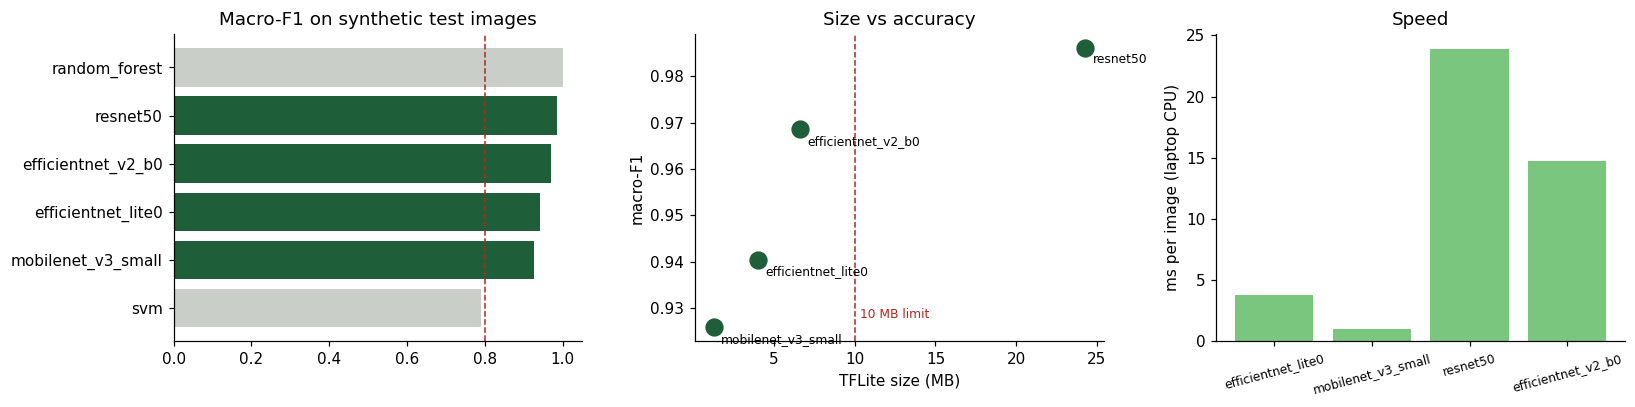

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
order = syn["macro-F1"].astype(float).sort_values().index
deep = {"efficientnet_lite0", "mobilenet_v3_small", "efficientnet_v2_b0", "resnet50"}
axes[0].barh(order, syn.loc[order, "macro-F1"].astype(float), color=["#1E5E39" if m in deep else "#C9CEC9" for m in order])
axes[0].axvline(0.80, color="#B3261E", ls="--", lw=1); axes[0].set_xlim(0, 1.05); axes[0].set_title("Macro-F1 on synthetic test images")
cnn = syn.loc[[m for m in syn.index if m in deep]]
axes[1].scatter(cnn["TFLite MB"].astype(float), cnn["macro-F1"].astype(float), s=120, color="#1E5E39")
for m in cnn.index: axes[1].annotate(m, (float(cnn.loc[m, "TFLite MB"]), float(cnn.loc[m, "macro-F1"])), fontsize=8, xytext=(5, -10), textcoords="offset points")
axes[1].axvline(10, color="#B3261E", ls="--", lw=1); axes[1].text(10.3, axes[1].get_ylim()[0] + 0.005, "10 MB limit", fontsize=8, color="#B3261E")
axes[1].set_xlabel("TFLite size (MB)"); axes[1].set_ylabel("macro-F1"); axes[1].set_title("Size vs accuracy")
axes[2].bar(cnn.index, cnn["laptop ms"].astype(float), color="#7BC67E"); axes[2].set_ylabel("ms per image (laptop CPU)")
axes[2].set_title("Speed"); axes[2].tick_params(axis="x", labelsize=8, rotation=15)
plt.tight_layout(); plt.show()

### 10.2 On real produce photos (AgriFreshNET)
The two phone-sized models were trained on real photos. The selection rule from the proposal is: among models that meet the spoilage-recall target, pick the best macro-F1; if two are within 0.01, pick the **smaller** one. The installed model is shown in Section 2.

posx and posy should be finite values


posx and posy should be finite values


posx and posy should be finite values


posx and posy should be finite values


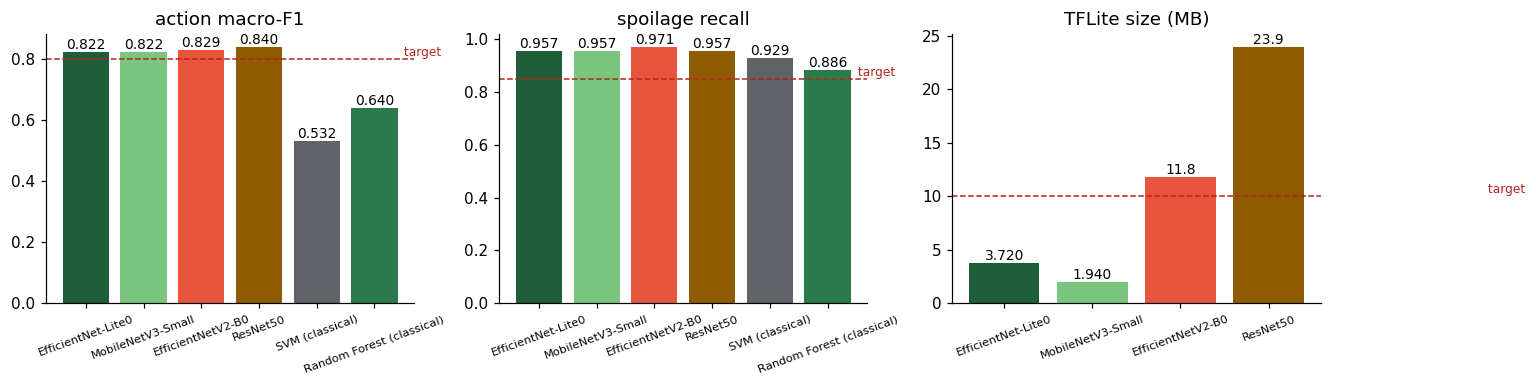

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, target in zip(axes, ["action macro-F1", "spoilage recall", "TFLite size (MB)"], [0.80, 0.85, 10]):
    vals = headline[col].astype(float)
    ax.bar(vals.index, vals.values, color=PALETTE[:len(vals)])
    ax.axhline(target, color="#B3261E", ls="--", lw=1); ax.text(len(vals) - 0.55, target, " target", color="#B3261E", va="bottom", fontsize=8)
    ax.set_title(col); ax.tick_params(axis="x", labelsize=7.5, rotation=20)
    for i, v in enumerate(vals): ax.text(i, v, f"{v:.3f}" if v < 5 else f"{v:.1f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

## 11. Running on the phone

### 11.1 Export to TensorFlow Lite
The exporter checks that the TFLite model gives the same top answer as the Keras model before it's accepted.

In [29]:
rows = []
for name, run in RUNS.items():
    e = load(run, "export.json")
    rows.append({"model": name, "quantization": e["quantization"], "size MB": e["size_mb"],
                 "same answer as Keras": f"{e['top1_agreement']:.0%}", "max probability difference": e["max_abs_prob_diff"],
                 "laptop CPU ms": round(e["laptop_cpu_ms_median"], 1)})
pd.DataFrame(rows).set_index("model")

,quantization,size MB,same answer as Keras,max probability difference,laptop CPU ms
model,,,,,
EfficientNet-Lite0,dynamic,3.72,100%,0.121,8.6
MobileNetV3-Small,float16,1.94,98%,0.014,2.4
EfficientNetV2-B0,float16,11.82,100%,0.004,20.4
ResNet50,dynamic,23.95,100%,0.069,36.6


### 11.2 Speed and export agreement as graphs

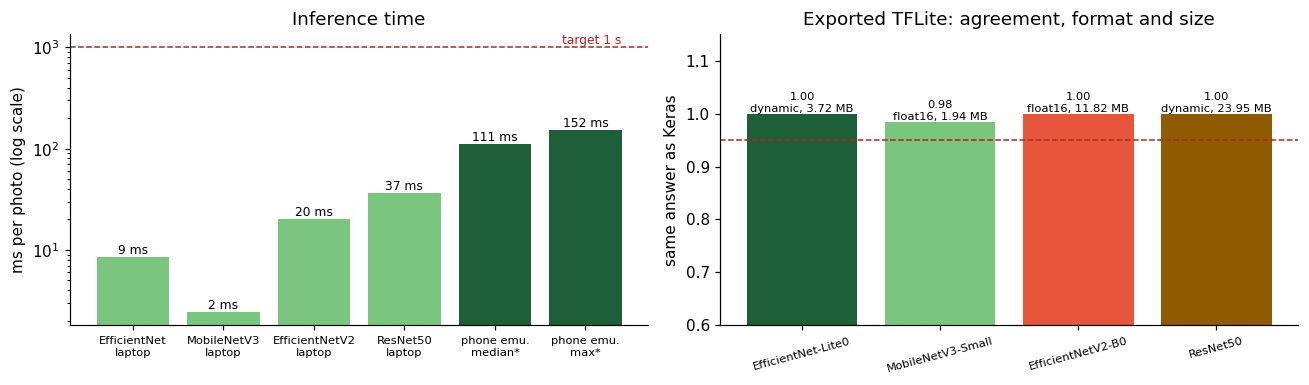

* emulator times were measured with an earlier installed model of similar size.
Full int8 changed the answer on 23% of images in an earlier test, so the exporter uses weight-only (dynamic) quantization and falls back to float16 when agreement drops below 95%.


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
lat = {f"{n.split('-')[0]}\nlaptop": load(r, "export.json")["laptop_cpu_ms_median"] for n, r in RUNS.items()}
lat.update({"phone emu.\nmedian*": 111, "phone emu.\nmax*": 152})
lat = pd.Series(lat)
bars = axes[0].bar(lat.index, lat.values, color=["#7BC67E"] * len(RUNS) + ["#1E5E39", "#1E5E39"])
axes[0].bar_label(bars, fmt="%.0f ms", fontsize=8); axes[0].axhline(1000, color="#B3261E", ls="--", lw=1)
axes[0].tick_params(axis="x", labelsize=7.5); axes[0].text(len(lat) - 0.6, 1000, "target 1 s", color="#B3261E", fontsize=8, va="bottom", ha="right")
axes[0].set_yscale("log"); axes[0].set_ylabel("ms per photo (log scale)"); axes[0].set_title("Inference time")
exp = {n: load(r, "export.json") for n, r in RUNS.items()}
names = list(exp)
bars = axes[1].bar(names, [exp[n]["top1_agreement"] for n in names], color=[MODEL_COLOR[n] for n in names])
axes[1].bar_label(bars, labels=[f'{exp[n]["top1_agreement"]:.2f}\n{exp[n]["quantization"]}, {exp[n]["size_mb"]} MB' for n in names], fontsize=7.5)
axes[1].axhline(0.95, color="#B3261E", ls="--", lw=1)
axes[1].set_ylim(0.6, 1.15); axes[1].set_ylabel("same answer as Keras"); axes[1].tick_params(axis="x", labelsize=7.5, rotation=15)
axes[1].set_title("Exported TFLite: agreement, format and size")
plt.tight_layout(); plt.show()
print("* emulator times were measured with an earlier installed model of similar size.")
print("Full int8 changed the answer on 23% of images in an earlier test, so the exporter uses weight-only (dynamic) "
      "quantization and falls back to float16 when agreement drops below 95%.")

### 11.3 Phone vs Python (on-device parity test)
`app/integration_test/parity_test.dart` runs the app's own code (Dart preprocessing, `tflite_flutter`, and the decision rule) on an Android emulator (Pixel 8, arm64) and compares it with Python on the same photos. The numbers below were measured with the previously installed model (EfficientNet-Lite0). The fixtures have been regenerated for the current model; re-run the test with `flutter test integration_test/parity_test.dart -d <device>`.

| Check | Result |
|---|---|
| Photos tested (12 JPEG + 6 lossless PNG) | 18 |
| **Same action shown on phone and in Python** | **18 / 18** |
| Max probability difference, PNG (identical pixels) | 0.025 (ARM vs x86 quantized kernels) |
| Max probability difference, JPEG (different JPEG decoders) | 0.069 |
| On-device inference, median / max | **111 ms / 152 ms** (target < 1 s) |

The parity test found a real bug. Dart's built-in image resize differed from Pillow's by up to 88 grey levels, which shifted probabilities by more than 0.13. The app now uses its own box resize, which matches Pillow pixel for pixel (unit-tested).

### 11.4 Release build
| | |
|---|---|
| Development environment | Python 3.11 venv or Docker image `harvestshelf-train:2.15` (TensorFlow 2.15.1; the 35 tests pass inside it), Flutter 3.32.5 pinned in `.fvmrc`, GitHub Actions in `.github/workflows/ci.yml`, `make data-public` downloads the dataset |
| APK size (arm64) | 13.2 MB with MobileNetV3-Small (target < 50 MB) |
| Permissions requested | none for network, camera, phone or storage. The build script fails if any appear. |

## 11b. Requirements traceability
Each requirement from the proposal is linked to the code, the tests and the evidence. This is the same table as `docs/requirements_traceability.md`.

In [31]:
display(Markdown((ROOT / "docs" / "requirements_traceability.md").read_text().split("\n", 3)[3]))


Status: ✅ done and verified · 🟡 done, waiting on field data · ⬜ not started

## Functional requirements

| ID | Requirement | Implementation | Tests | Evidence | Status |
|---|---|---|---|---|---|
| FR1 | Capture a photo with the camera or choose one from the gallery | `app/lib/screens/scan_screen.dart` (`image_picker`, max 1280 px, no re-compression) | `app/test/app_navigation_test.dart` (home renders the scan actions) | Emulator: gallery scan and camera scan (notebook §12) | ✅ |
| FR2 | Check image quality; reject photos that are too dark, too bright, blurred or unsupported | `app/lib/services/image_quality_service.dart` (brightness, sharpest-tile sharpness), `unusable` class in the model | `app/test/image_quality_test.dart` (incl. matching Python on `shared/quality_cases.json`), `training/tests/test_quality*.py` | Blur check rejects 0.8% of in-focus photos and catches 91–100% of blurred ones; 100% of other produce rejected on the test set (notebook §5.4, §8) | ✅ |
| FR3 | Run the bundled TFLite model on the phone; return class and confidence | `app/lib/services/classifier_service.dart` (`tflite_flutter`, background isolate), `app/lib/services/preprocessing_service.dart`, `app/lib/services/resize.dart` | `app/integration_test/parity_test.dart` (on device), `app/test/resize_test.dart` (Pillow-exact) | Phone and Python showed the same action on 18/18 photos (notebook §11) | ✅ |
| FR4 | Map the result to Fresh / Sell Soon / Discount Today / Spoilage Risk / Uncertain, with guidance text | `app/lib/services/decision_mapper.dart`, `app/assets/guidance_rules.json`, `app/lib/screens/result_screen.dart` | `app/test/decision_mapper_test.dart` and `training/tests/test_decision.py` (same cases from `shared/decision_cases.json`), `app/test/widget_test.dart` | Notebook §4 shows every decision case passing | ✅ |
| FR5 | Save each scan (crop, action, confidence, time) in SQLite; let the seller view past scans | `app/lib/data/database.dart` (v2 schema), `app/lib/data/repositories.dart`, `app/lib/screens/history_screen.dart` | `app/test/data_test.dart` (per-user history, database upgrade v1→v2) | Screenshots in `docs/screenshots/` | ✅ |
| FR6 | Researcher exports an anonymous test log | `app/lib/services/export_service.dart`, Profile → Export test log (researchers only) | `app/test/data_test.dart` (CSV has no names), `app/test/app_navigation_test.dart` (sellers don't see export) | `evaluation/analysis.py latency` reads the CSV | ✅ |
| FR7 *(new)* | Local accounts: register, log in/out, roles, PIN reset, delete user | `app/lib/services/auth/` (PBKDF2 PINs, lockout), `app/lib/screens/auth/`, `app/lib/screens/manage_users_screen.dart` | `app/test/auth_test.dart`, `app/test/pin_hasher_test.dart` (matches Python), `app/test/app_navigation_test.dart` (full flow) | Notebook §12 | ✅ |

## Non-functional requirements

| ID | Requirement | How it's met | Check | Evidence | Status |
|---|---|---|---|---|---|
| NFR1 | Works offline | No INTERNET permission; model and data are bundled | `scripts/build_release.sh` fails if INTERNET appears | Release manifest permission list | ✅ |
| NFR2 | Inference < 1 s on a 3–4 GB phone | Small TFLite model, background isolate, 4 threads | `parity_test.dart` logs timing; app CSV `inference_ms` | About 110 ms median, 152 ms max on the emulator (notebook §11). Not yet measured on a real 3–4 GB phone. | 🟡 |
| NFR3 | Usability: simple words and colours; SUS ≥ 68 | Clean 3-tab design, one main action per screen, accessible colours, large text | Large-text and landscape layout tests | SUS needs at least 15 sellers (`evaluation/`) | 🟡 |
| NFR4 | App < 50 MB | Split-per-ABI APKs, model under 10 MB | `scripts/build_release.sh` prints sizes | About 13–15 MB APK | ✅ |
| NFR5 | Privacy: no data leaves the phone | No network permission; phone/storage permissions removed; export has no names | `build_release.sh` permission check; CSV test | The app now stores display names and usernames **on the phone** (proposal update needed) | ✅ |
| NFR6 | Reliability: Uncertain instead of a guess | Quality check, `unusable` class, `t_conf` | `decision_mapper_test.dart`, shared cases | Notebook §7–8 | ✅ |

## Objectives and research questions

| Proposal item | Delivered | Where |
|---|---|---|
| Objective 1: labeling guide and requirements | ✅ | `docs/labeling_guide.md`, `docs/data_collection.md`, this file |
| Objective 2: offline prototype with on-device TFLite, decision rules, local history | ✅ | `app/` |
| Objective 3: macro-F1 ≥ 0.80, Spoilage recall ≥ 0.85 | 🟡 Met on public data; Rwandan photos still needed | Notebook §2, §7 |
| Objective 3: SUS ≥ 68, +15 points agreement | 🟡 Protocols and analysis ready | `evaluation/`, notebook §13 |
| RQ1: categories, data and user needs | ✅ | Labeling guide, proposal |
| RQ2: integrating capture, preprocessing, TFLite and SQLite offline | ✅ | App architecture (notebook §4) |
| RQ3: how far the targets are met | 🟡 Public data now; field results pending | Notebook |

## Model comparison (proposal Section 3.4.5)

| Candidate | Status |
|---|---|
Test results on held-out AgriFreshNET capture sessions (public data, not Rwandan markets):

| Candidate | Macro-F1 | Spoilage recall | Phone size | Role |
|---|---|---|---|---|
| **EfficientNet-Lite0** | 0.822 | 0.957 | 3.7 MB | **Installed in the app** |
| MobileNetV3-Small | 0.822 | 0.957 | 1.9 MB | Baseline only; excluded from the app at the project owner's request |
| ~~MobileNetV2~~ → **EfficientNetV2-B0** | 0.829 | 0.971 | 11.8 MB | Replaced at the project owner's request; just over the 10 MB limit |
| ResNet50 | 0.840 | 0.957 | 24.0 MB | Accuracy reference; too large for the phone |
| Random Forest | 0.640 | 0.886 | n/a | Classical baseline |
| SVM | 0.532 | 0.929 | n/a | Classical baseline |

The deep models beat the classical baselines by about 0.2–0.3 macro-F1, which supports the proposal's choice of a CNN. The phone model is chosen by the rule in `training/tools/public_experiment.py`: fits within 10 MB, its TFLite agrees with Keras, then the best macro-F1 among models meeting spoilage recall.


## 12. The app
These screens were rendered with demo data, using the app's real fonts and theme.

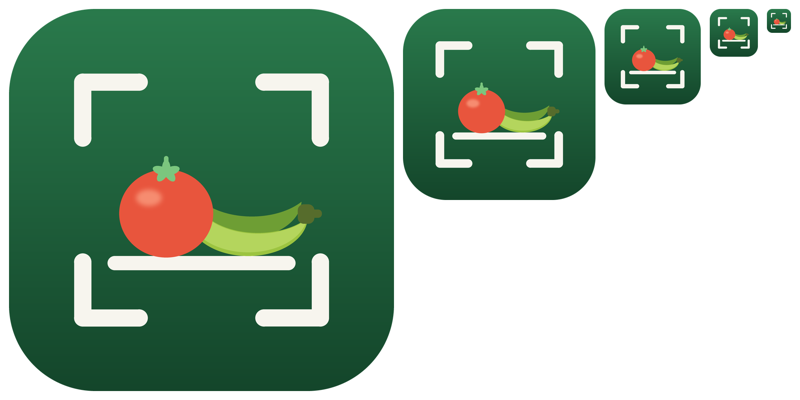

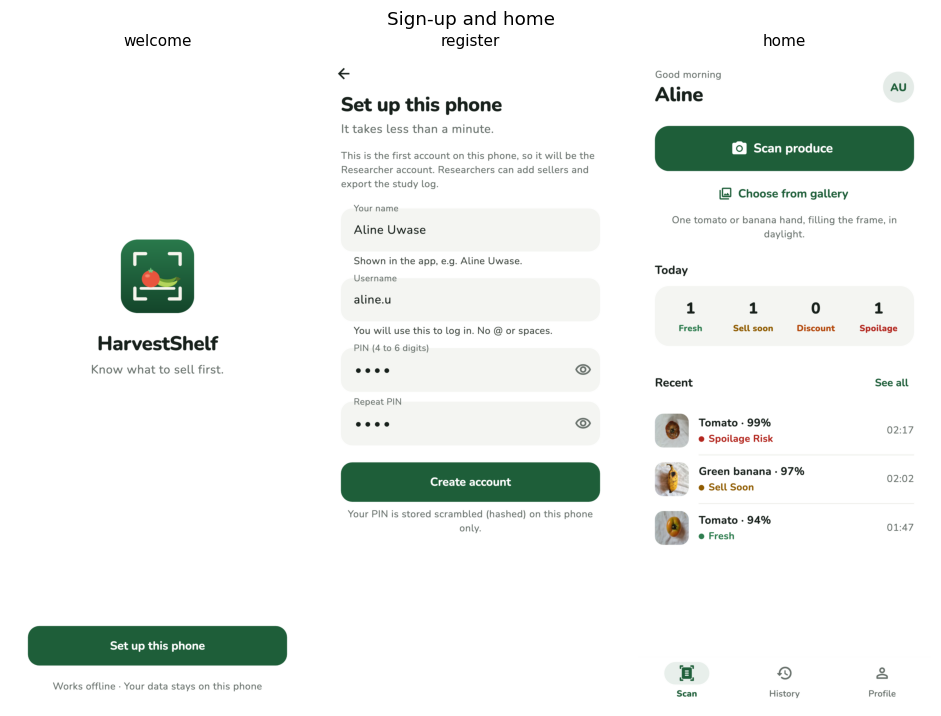

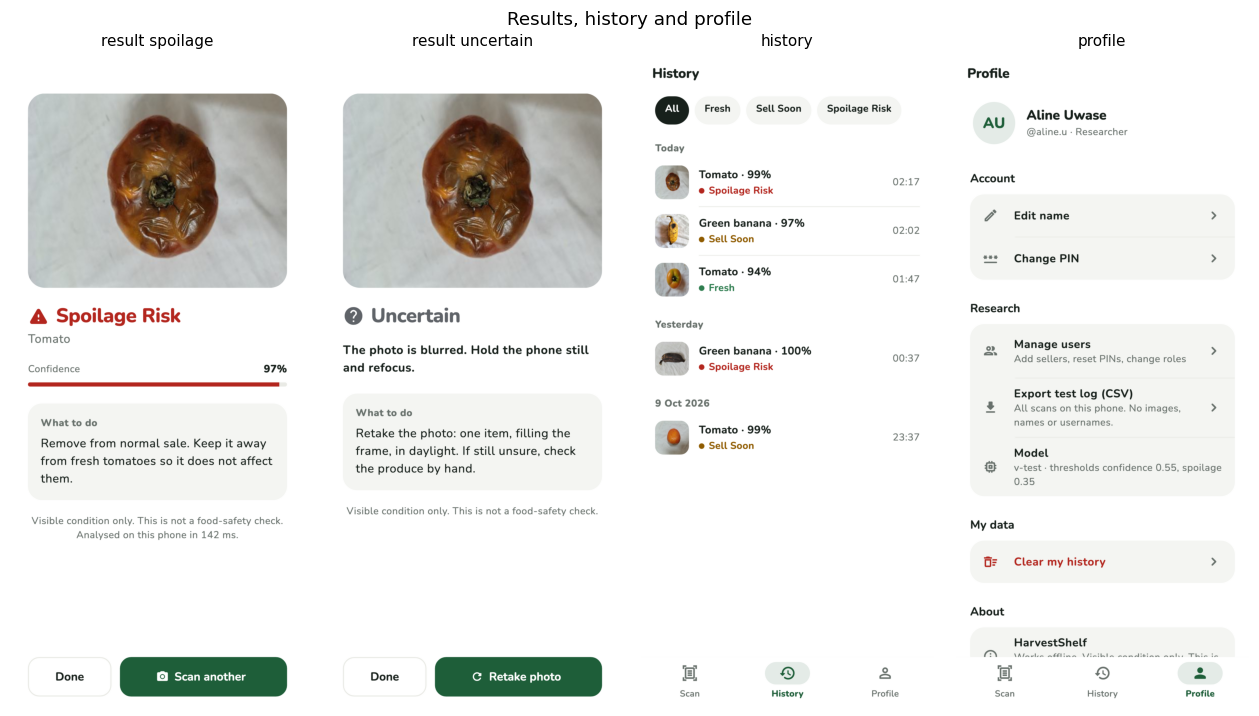

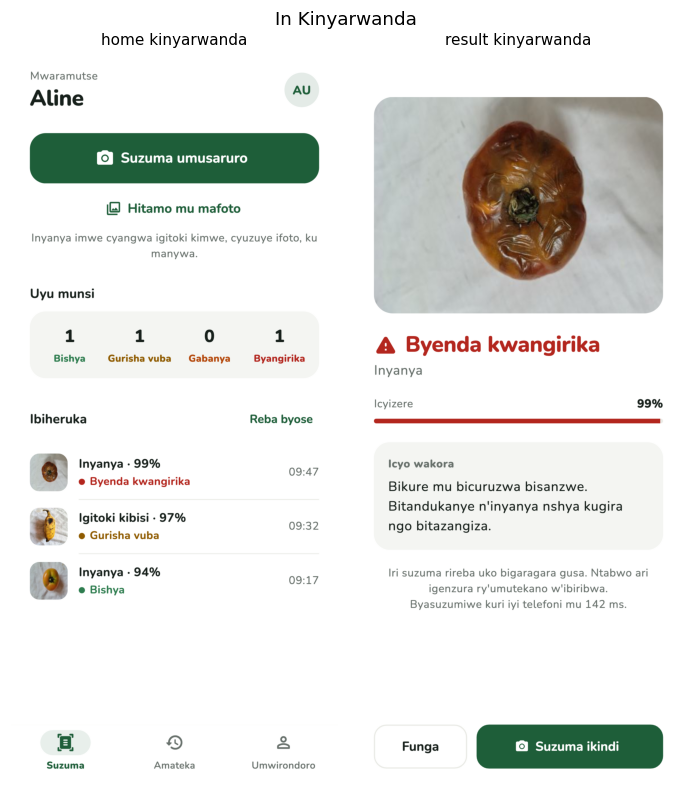

In [32]:
def show_shots(names, title, width=2.9):
    ims = [Image.open(SHOTS / f"{n}.png") for n in names if (SHOTS / f"{n}.png").exists()]
    fig, axes = plt.subplots(1, len(ims), figsize=(width * len(ims), width * 2.25))
    for ax, im, n in zip(np.atleast_1d(axes), ims, names):
        ax.imshow(im); ax.axis("off"); ax.set_title(n.split("_", 1)[1].replace("_", " "), fontsize=10)
    fig.suptitle(title, y=0.99); plt.tight_layout(); plt.show()

display(Image.open(SHOTS / "00_logo.png").resize((800, 400)))
show_shots(["01_welcome", "02_register", "03_home"], "Sign-up and home")
show_shots(["06_result_spoilage", "07_result_uncertain", "04_history", "05_profile"], "Results, history and profile")
show_shots(["08_home_kinyarwanda", "09_result_kinyarwanda"], "In Kinyarwanda", width=3.2)

**Features:**
- **Scan** with the camera or from the gallery. A quality check runs first, then the on-device model and the decision rule. The result shows one action, a confidence bar (only for direct model answers), what to do, and the disclaimer.
- **History:** your own scans, grouped by day, with filters by action.
- **Accounts, all offline:**
  - Register and log in with a username and a 4–6 digit PIN. PINs are stored as PBKDF2-SHA256 hashes, and obvious PINs are refused.
  - Five wrong PINs lock the account for 30 seconds.
  - The first account on a phone becomes the **Researcher**. Researchers can add users, change roles, reset PINs and delete users (with their scans). Everyone else is a **Seller**.
- **Export (researchers only):** an anonymous CSV log for evaluation, with a user number but no names, usernames or images.
- **Logo:** drawn from basic shapes in `scripts/make_logo.py`: a tomato and a hand of green cooking bananas on a market shelf, inside camera scan corners.

- **Languages:** English and **Kinyarwanda**, switchable on the Welcome screen and in Profile, and remembered on the phone. The Kinyarwanda still needs review by a native speaker.
- **Accessibility:** layout is tested on a small phone, in landscape, and at 1.6× and 2× system text; key controls have screen-reader labels.

**Tests:** 74 Flutter tests (decision rule, quality check matched to Python, Pillow-exact resize, PIN hashing against Python's values, accounts, database upgrades, full app flow, layout at large text and in landscape, Kinyarwanda) and 35 Python tests.

## 13. User evaluation (pending)
The SUS questionnaire, the seller agreement study and the field latency log run with sellers in the markets. The cell below analyses them as soon as the CSV files in `evaluation/` have data.

In [33]:
sys.path.insert(0, str(ROOT / "evaluation"))
import analysis
ev = ROOT / "evaluation"
def has_rows(p): return p.exists() and len(pd.read_csv(p)) > 0
checks = [
    ("SUS (target mean >= 68, at least 15 sellers)", ev / "usability" / "sus_results.csv",
     lambda: analysis.cmd_sus(str(ev / "usability" / "sus_results.csv"))),
    ("Agreement with experts (target +15 points)", ev / "agreement_study" / "seller_sorts.csv",
     lambda: analysis.cmd_agreement(str(ev / "agreement_study" / "seller_sorts.csv"), str(ev / "agreement_study" / "expert_labels.csv"))),
]
for title, path, run in checks:
    print(f"== {title}")
    run() if has_rows(path) else print(f"   no data yet ({path.relative_to(ROOT)} is an empty template)\n")

# Charts appear here automatically once the study files have data.
sus_p, sorts_p = ev / "usability" / "sus_results.csv", ev / "agreement_study" / "seller_sorts.csv"
if has_rows(sus_p) or has_rows(sorts_p):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    if has_rows(sus_p):
        sus = pd.read_csv(sus_p); sus["sus"] = sus.apply(analysis.sus_score, axis=1)
        axes[0].hist(sus.sus, bins=10, range=(0, 100), color="#1E5E39"); axes[0].axvline(68, color="#B3261E", ls="--")
        axes[0].set_title(f"SUS scores (mean {sus.sus.mean():.1f}, n={len(sus)})"); axes[0].set_xlabel("SUS")
    if has_rows(sorts_p):
        m_ = pd.read_csv(sorts_p).merge(pd.read_csv(ev / "agreement_study" / "expert_labels.csv"), on="item_id")
        m_["agree"] = m_.seller_label == m_.expert_label
        per = m_.pivot_table(index="participant_id", columns="condition", values="agree", aggfunc="mean")
        for _, r_ in per.iterrows(): axes[1].plot([0, 1], [r_.without_app, r_.with_app], color="#7BC67E", alpha=0.6)
        axes[1].plot([0, 1], [per.without_app.mean(), per.with_app.mean()], color="#1E5E39", lw=3, marker="o")
        axes[1].set_xticks([0, 1], ["without app", "with app"]); axes[1].set_title("Agreement with experts per seller")
    plt.tight_layout(); plt.show()
else:
    print("(Charts for SUS and agreement will appear here once the study data is entered.)")
logs = sorted((ev / "device_logs").glob("*.csv"))
print("== On-device latency from exported app logs")
analysis.cmd_latency([str(p) for p in logs]) if logs else print("   no app logs exported yet (Profile > Export test log)")

== SUS (target mean >= 68, at least 15 sellers)
   no data yet (evaluation/usability/sus_results.csv is an empty template)

== Agreement with experts (target +15 points)
   no data yet (evaluation/agreement_study/seller_sorts.csv is an empty template)

(Charts for SUS and agreement will appear here once the study data is entered.)
== On-device latency from exported app logs
   no app logs exported yet (Profile > Export test log)


## 14. Limitations, issues found, next steps

**Limitations of the current model:**
- It was trained on **Bangladesh photos of single items on a white cloth**, not Rwandan market stalls.
- The bananas are mostly **yellow** ripening ones, not green cooking bananas (matooke).
- There are **no Discount Today examples**. The interim model can't learn that action.
- Accuracy targets are not met on this public data (see Section 2).

**Problems found and fixed while building:**

| Problem | Effect | Fix |
|---|---|---|
| Augmented copies in AgriFreshNET leaked into the test set | Inflated scores (see the results history) | Drop `aug_*` copies; split by capture session |
| Blur check used the whole image | 66% of in-focus fresh tomatoes rejected or relabelled | Sharpest-tile measure, threshold chosen from data; Python and app tested to match |
| Pillow-matching resize was off at exact ratios such as 1.5× | Small brightness and sharpness differences | Boundary rule fixed; 1.5× case added to the tests |
| TF1 Hub EfficientNet-Lite0 couldn't be fine-tuned | Training crashed | `HubKerasLayerV1V2` (the TFLite Model Maker approach) |
| Full int8 quantization | Phone answer differed on up to 23% of images | Dynamic quantization by default, float16 fallback, agreement check |
| Dart resize ≠ Pillow resize | Probabilities shifted by up to 0.13 | Custom box resize, pixel-exact |
| JPEG re-compression in the image picker | Flipped a borderline photo from Spoilage Risk to Sell Soon | Removed `imageQuality` |
| Implied phone and storage permissions from the TFLite GPU library | Privacy issue (NFR5) | Removed in the manifest; the build checks for them |
| History/Settings screens crashed, layout overflow on small phones | App bugs | Fixed, with tests |

**Next steps:**
1. Collect Rwandan market photos: at least 3 markets in Nyabihu and Rusizi, at least 5 days, at least 300 per action per crop. See `docs/data_collection.md` and `docs/labeling_guide.md`.
2. Fine-tune the interim model on those photos and compare it with training from ImageNet weights only.
3. Run the SUS and seller agreement studies with at least 15 sellers.

**Updates needed in the proposal:**
- **Section 3.4.3:** public data was used for an interim model.
- **Section 3.4.3 and NFR5:** the app now stores each user's name and username on the phone.
- **Section 3.3:** add accounts as FR7.
- **Ethics (Section 3.8):** deleting an account deletes its scans, and the export contains only an anonymous user number.
- **Section 2.6:** the public-data results above support its argument.

## 15. How to reproduce

```bash
cd training
python3.11 -m venv .venv && .venv/bin/pip install -r requirements.txt
make test                    # 35 Python tests
make smoke                   # whole pipeline on generated images

# Interim model on AgriFreshNET (download "Processed Data.zip" from Mendeley, DOI 10.17632/42m5tb7yv9.1)
python -m tools.public_experiment --source "sandbox/public/extracted/Processed Data" \
       --models efficientnet_lite0 mobilenet_v3_small --install-in-app

# All six candidate models on generated images
python -m tools.synthetic_experiment

# With real Rwandan photos in data/raw + data/metadata.csv
make clean-data split cv classical compare
make final MODEL=efficientnet_lite0
make thresholds RUN=experiments/<run>
python -m src.evaluate --run experiments/<run> --split test --confirm-test
make export RUN=experiments/<run> && ../scripts/copy_model_to_app.sh

# App
cd ../app && flutter test && ../scripts/build_release.sh
flutter test integration_test/parity_test.dart -d <device>
```